In [4]:
from matplotlib import colors
from matplotlib.patches import Rectangle
from matplotlib.transforms import Affine2D
from mpl_toolkits.axisartist.grid_finder import DictFormatter
from scipy.spatial.distance import pdist # <- for dendrograms
import json
import math
import matplotlib.font_manager as font_manager
import matplotlib.lines as mlines
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import mpl_toolkits.axisartist.floating_axes as floating_axes
import numpy as np
import pandas as pd
import scipy.cluster.hierarchy as sch # <- for dendrograms

In [6]:
def from_upper_triu(vector_repr, matrix_len, num_diags):
    z = np.zeros((matrix_len,matrix_len))
    triu_tup = np.triu_indices(matrix_len,num_diags)
    z[triu_tup] = vector_repr
    for i in range(-num_diags+1,num_diags):
        set_diag(z, np.nan, i)
    return z + z.T

def set_diag(arr, x, i=0):
    start = max(i, -arr.shape[1] * i)
    stop = max(0, (arr.shape[1] - i)) * arr.shape[1]
    step = arr.shape[1] + 1
    arr.flat[start:stop:step] = x
    return arr

def setup_axes1(fig, rect, angle):
    tr = Affine2D().scale(2, 2).rotate_deg(angle)

    #We create dictionarys to keep the xticks and yticks after the rotation
    dictio={i:str(val) for i,val in enumerate(np.arange(-.5, 449, 10).tolist())}
    reversedictio={i:dictio[val] for i,val in enumerate(list(reversed(sorted(dictio.keys()))))}
    grid_helper = floating_axes.GridHelperCurveLinear(
        tr, extremes=(-0.5, 448.5,-0.5, 448.5), tick_formatter1= DictFormatter(dictio),
        tick_formatter2=DictFormatter(reversedictio))

    ax1 = floating_axes.FloatingSubplot(fig, rect, grid_helper=grid_helper)
    
    # remove axes
    ax1.axis("off")    
    ax1.axis["bottom"].set_visible(False)
    ax1.axis["top"].set_visible(False)
    ax1.axis["right"].set_visible(False)
    ax1.axis["left"].set_visible(False)


    fig.add_subplot(ax1) 
    aux_ax = ax1.get_aux_axes(tr)
    grid_helper.grid_finder.grid_locator1._nbins = 448    #Number of rows
    grid_helper.grid_finder.grid_locator2._nbins = 448    #Number of columns
    return aux_ax

In [13]:
def load_individual_map(filename):
    # with open('/wynton/group/capra/projects/pan_3d_genome/data/predictions/HFF/3d_predictions_%s_%s.txt' % (ind, chr)) as file:
    #     lines = [ line.strip() for line in file ]
    #     for line in lines:
    #         if (f'{chr}\t{start}') in line:
    #             ind_vector = line.split('\t')
    #             ind_vector = ind_vector[2:]
    ind_vector = np.loadtxt(filename)
    ind_mat = from_upper_triu(ind_vector, 448, 2)
    mask =  np.tri(ind_mat.shape[0], k = -1)
    ind_mat = np.ma.array(ind_mat, mask = mask).T

    return ind_mat

In [7]:
def annotations(chr, start):
    # assign a few variables for the "tracks" below
    map_x_min = (start+65536)
    map_x_max = (start+((2**20)-65536))
            
    # exons
    # exons = pd.read_csv('/wynton/group/capra/projects/pan_3d_genome/data/annotations/panTro6_exons.bed', sep = '\t', header = None, names = ['chr','start','end','gene'])
    # exons = exons[(exons['chr'] == chr) & (exons['start'] >= start) & (exons['start'] < map_x_max)]
    # exons['end'].values[exons['end'] > map_x_max] = map_x_max
    
    # exons['start'] = (exons['start'] - (start + 65536)) / 2048
    # exons['end'] = (exons['end'] - (start + 65536)) / 2048
    # exons['length'] = exons['end'] - exons['start']
    # exons = exons[exons['end'] >= 0] # remove values less than zero
    
    # exon_genes = pd.unique(exons['gene']).tolist()
    # exon_starts = exons['start'].values.tolist()
    # exon_lengths = exons['length'].values.tolist()

    # genes
    genes = pd.read_csv('/Users/wanjun/Desktop/akita_visualize/grch38_gene_annotations.bed', sep = '\t', header = None, names = ['chr','start','end','gene'], skiprows=1)
    genes = genes[(genes['chr'] == chr) & (genes['start'] >= start) & (genes['start'] < map_x_max)]
    exon_genes = pd.unique(genes['gene']).tolist()
    genes = genes[genes['gene'].isin(exon_genes)]
    
    genes['start'].values[genes['start'] < map_x_min] = map_x_min
    genes['end'].values[genes['end'] > map_x_max] = map_x_max
    genes['start'] = (genes['start'] - map_x_min) / 2048
    genes['end'] = (genes['end'] - map_x_min) / 2048
  
    genes['length'] = genes['end'] - genes['start']
    gene_starts = genes['start'].values.tolist()
    gene_lengths = genes['length'].values.tolist()
    
    # gene names
    gene_midpoints = (genes['length']/2) + genes['start'].values.tolist()

    # phastCons
    phastCons = pd.read_csv('/Users/wanjun/Desktop/akita_visualize/phastConsElements100way_hg38.bed', sep = '\t', header = None, names = ['chr','start','end','name','score'], skiprows=1)
    phastCons = phastCons[(phastCons['chr'] == chr) & (phastCons['start'] >= start) & (phastCons['start'] < start+((2**20)-65536))]
    phastCons['end'].values[phastCons['end'] > map_x_max] = map_x_max
    phastCons['start'] = (phastCons['start'] - (start + 65536)) / 2048
    phastCons['end'] = (phastCons['end'] - (start + 65536)) / 2048
    phastCons['length'] = phastCons['end'] - phastCons['start']
    phastCons_starts = phastCons['start'].values.tolist()
    phastCons_lengths = phastCons['length'].values.tolist()
    
    # CTCF
    CTCF = pd.read_csv('/Users/wanjun/Desktop/akita_visualize/ctcf_full_merged_hg38.bed', sep = '\t', header = None, names = ['chr','start','end'])
    CTCF = CTCF[(CTCF['chr'] == chr) & (CTCF['start'] >= start) & (CTCF['start'] < start+((2**20)-65536))]
    CTCF['end'].values[CTCF['end'] > map_x_max] = map_x_max
    CTCF['start'] = (CTCF['start'] - (start + 65536)) / 2048
    CTCF['end'] = (CTCF['end'] - (start + 65536)) / 2048
    CTCF['length'] = CTCF['end'] - CTCF['start']
    CTCF_starts = CTCF['start'].values.tolist()
    CTCF_lengths = CTCF['length'].values.tolist()


    return gene_starts, gene_lengths, gene_midpoints, exon_genes, phastCons_starts, phastCons_lengths, CTCF_starts, CTCF_lengths #,exon_starts, exon_lengths 

In [16]:
def map_comparison_no_delta_with_annotations(filename1, filename2, window, save, figure_width, figure_height, plot_filename):
    chr = window.split('_')[0]
    start = int(window.split('_')[1])

    ind1_mat = load_individual_map(filename1)
    ind2_mat = load_individual_map(filename2)
    
    fig1, axes = plt.subplots(2, figsize=(figure_width,figure_height))
    # fig1, axes = plt.subplots(2, 1, figsize=(4.8,6.8))
    
    fig1.delaxes(axes[0])
    fig1.delaxes(axes[1])
    
    #ax0 = setup_axes1(fig1, 131, -45)
    #ax1 = setup_axes1(fig1, 132, -45)
    ax0 = setup_axes1(fig1, 211, -45)
    ax1 = setup_axes1(fig1, 212, -45)


    ax0.set_position([0, 0.43, 1, 1])
    ax1.set_position([0, 0, 1, 1])
    
    ax0.matshow(ind1_mat, cmap = 'RdBu_r', vmin = -2, vmax = 2)
    ax1.matshow(ind2_mat, cmap = 'RdBu_r', vmin = -2, vmax = 2)
    
    subplots = [ax0,ax1]
    
    # add border to map
    for n in subplots:
        n.plot([-1, 447], [0, 448], color = 'black', linewidth = 1) # bottom line
        n.plot([-1, 447], [448, 448], color = 'black', linewidth = 1) # right line
        n.plot([-1, -1], [448, 0], color = 'black', linewidth = 1) # left line
    
    # add 'x-axis' ticks
    first = start + 65536
    rounded = math.ceil(first / 100000) * 100000
    diff = rounded - first
    cell = diff/2048
    
    x_list = np.arange(cell, 440, (100000/2048))
        
    for n in subplots:
        for x in x_list:
            n.plot(x, x, color = 'black', marker = '|', markersize = 15*0.75)
    
    # add 'x-axis' labels
    y_list = np.arange((rounded/1000000), ((rounded/1000000)+0.9), 0.1)
    for n in subplots:
        for x, y in zip(x_list[::2], (y_list[::2])):
            n.text(x+18, x-18, '%.1f' % y, horizontalalignment = 'center', verticalalignment = 'top', fontsize = 9)
    
    gene_starts, gene_lengths, gene_midpoints, exon_genes, phastCons_starts, phastCons_lengths, CTCF_starts, CTCF_lengths = annotations(chr, start)
    #,exon_starts, exon_lengths
    # plot tracks
    # for x, y in zip(exon_starts, exon_lengths):
    #     ax2.add_patch(Rectangle((x+70, x-70), width = y, height = 25 * 0.75, angle = 45, color = 'black', lw = 1))
    for x, y in zip(gene_starts, gene_lengths):
        ax1.plot([(x+63.5), ((x+y)+63.5)],[(x-63.5), ((x+y)-63.5)], color = 'black') # line will default to bottom of exon rectangle so adjust coordinates if exon height changes
    for x, y in zip(gene_midpoints, exon_genes):
        ax1.text(x+75, x-75, y, horizontalalignment = 'center', verticalalignment = 'top', style = 'italic', fontsize = 7)
    for x, y in zip(CTCF_starts, CTCF_lengths):
        ax1.add_patch(Rectangle((x+115, x-115), width = y, height = 25 * 0.75, angle = 45, color = 'grey', lw = 1))
    for x, y in zip(phastCons_starts, phastCons_lengths):
        ax1.add_patch(Rectangle((x+145, x-145), width = y, height = 25 * 0.75, angle = 45, color = 'goldenrod', lw = 1))
    
    # track labels
    for n in subplots:
        n.text(0, -36, chr, horizontalalignment = 'right', verticalalignment = 'top', fontsize = 10)
    # track labels
    ax1.text(37.5, -82.5, 'Genes', horizontalalignment = 'right', verticalalignment = 'center',  fontsize = 10)
    ax1.text(87.5, -127.5, 'CTCF', horizontalalignment = 'right', verticalalignment = 'center',  fontsize = 10)
    ax1.text(117.5, -157.5, 'Cons', horizontalalignment = 'right', verticalalignment = 'center', fontsize = 10)

    plt.subplots_adjust(hspace=0.5)
    
    # save and show plot
    if save == 'yes':
        plt.savefig('/Users/wanjun/Desktop/akita_visualize/' + plot_filename, bbox_inches = 'tight', transparent = True)
        print('Comparisons saved.')
    plt.show()

Comparisons saved.


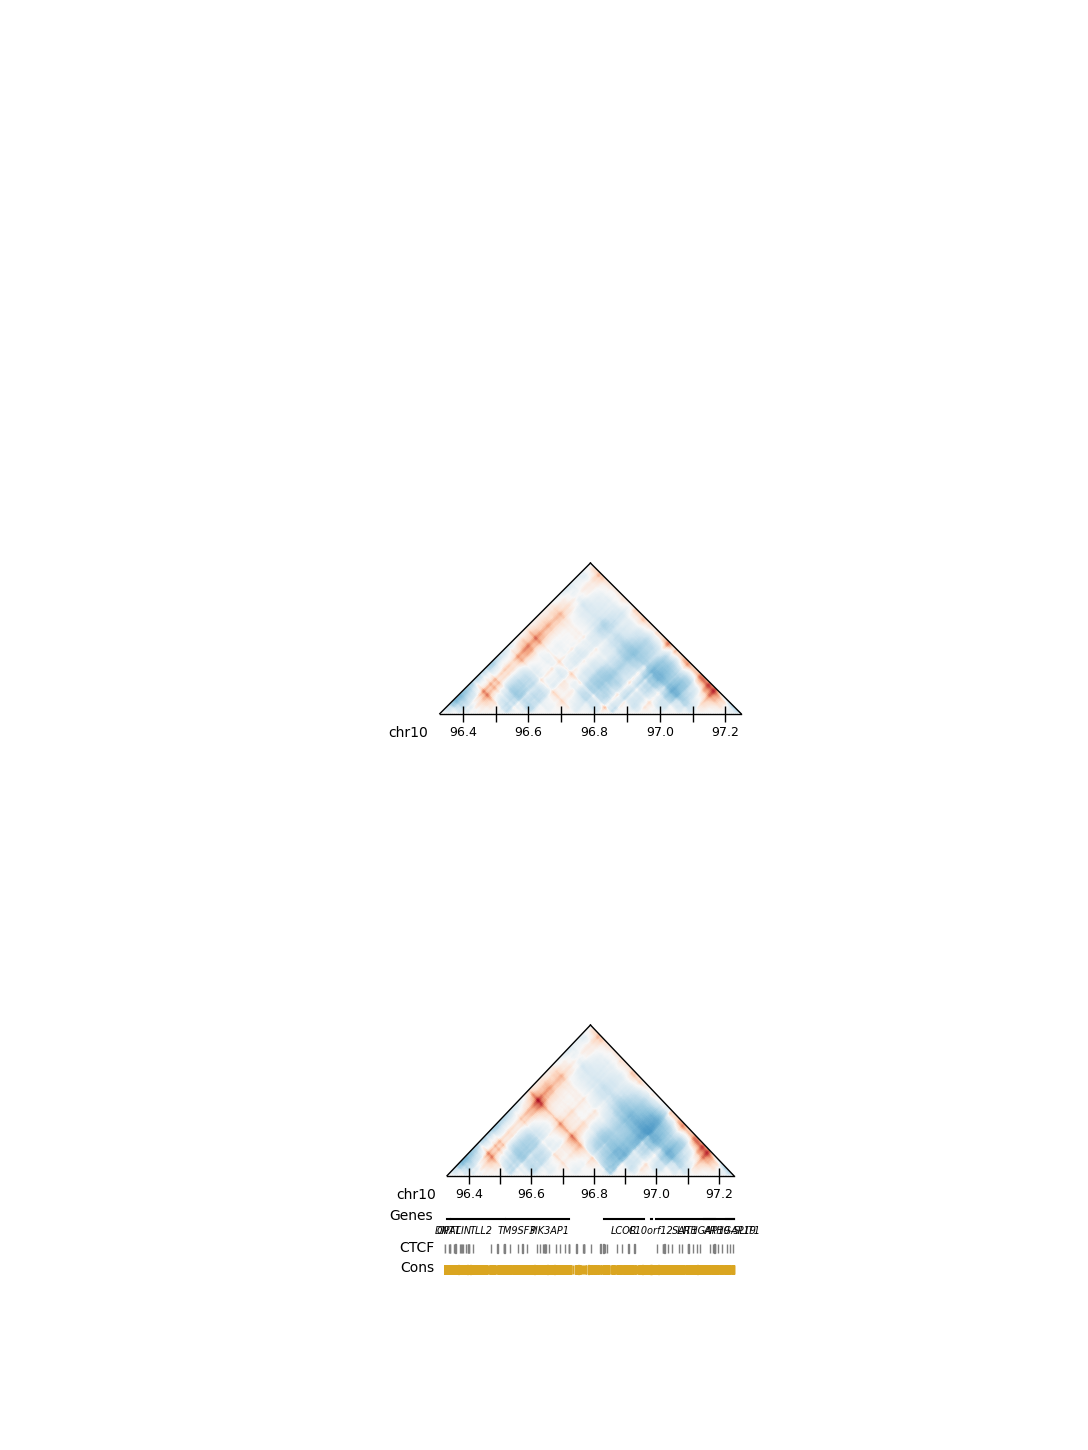

Comparisons saved.


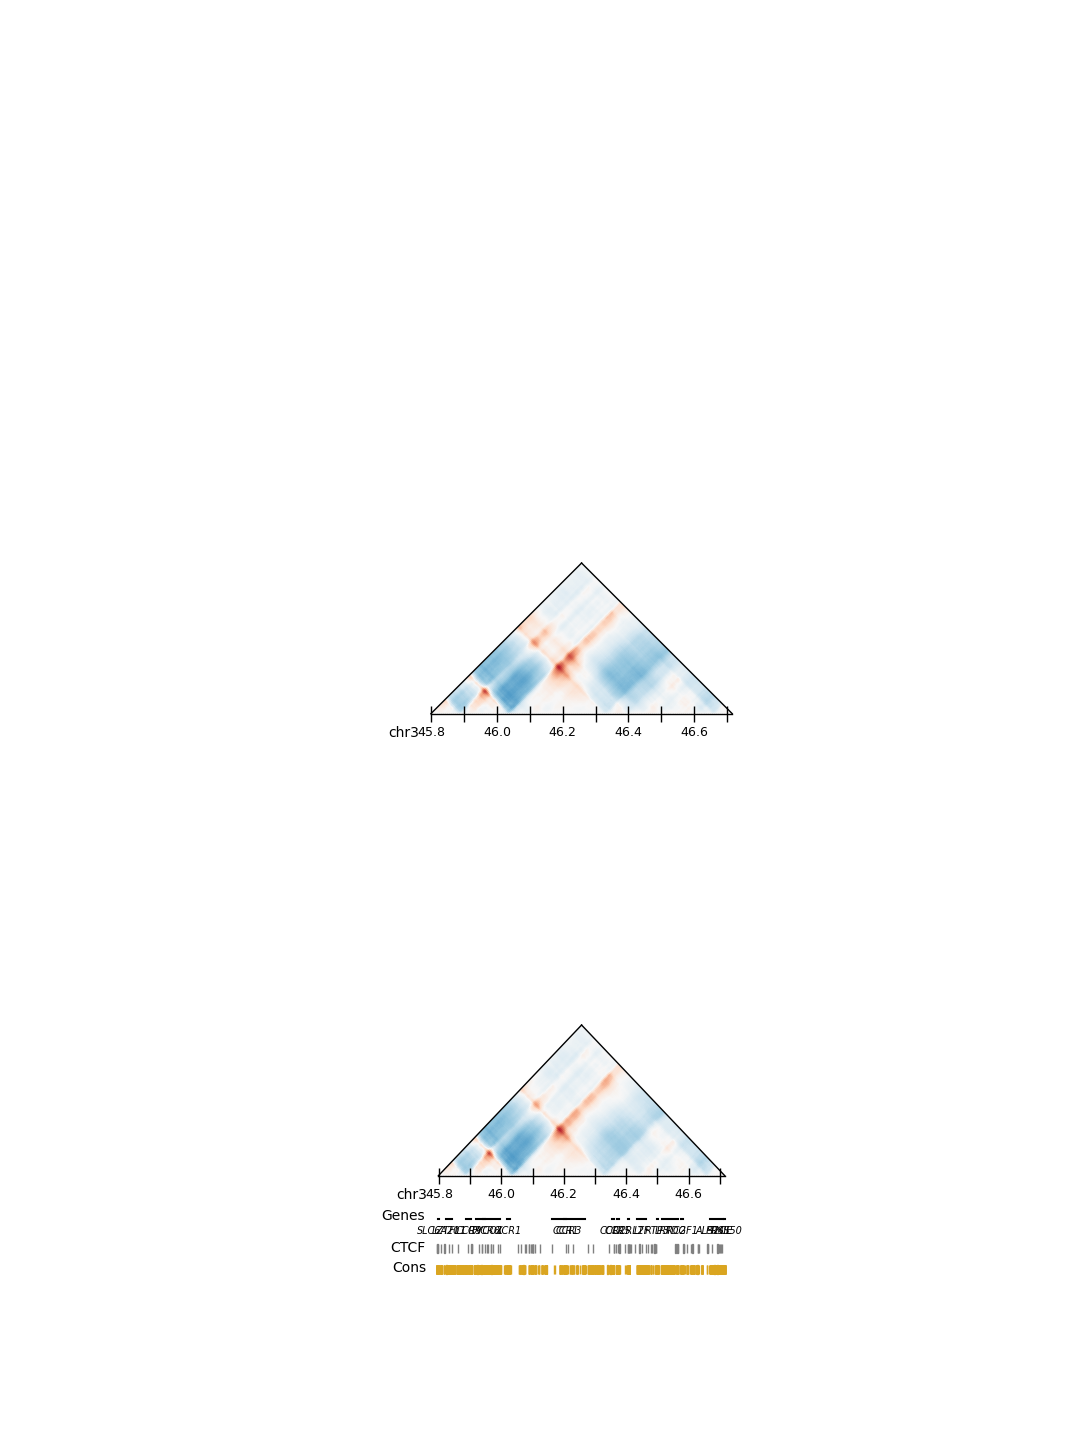

Comparisons saved.


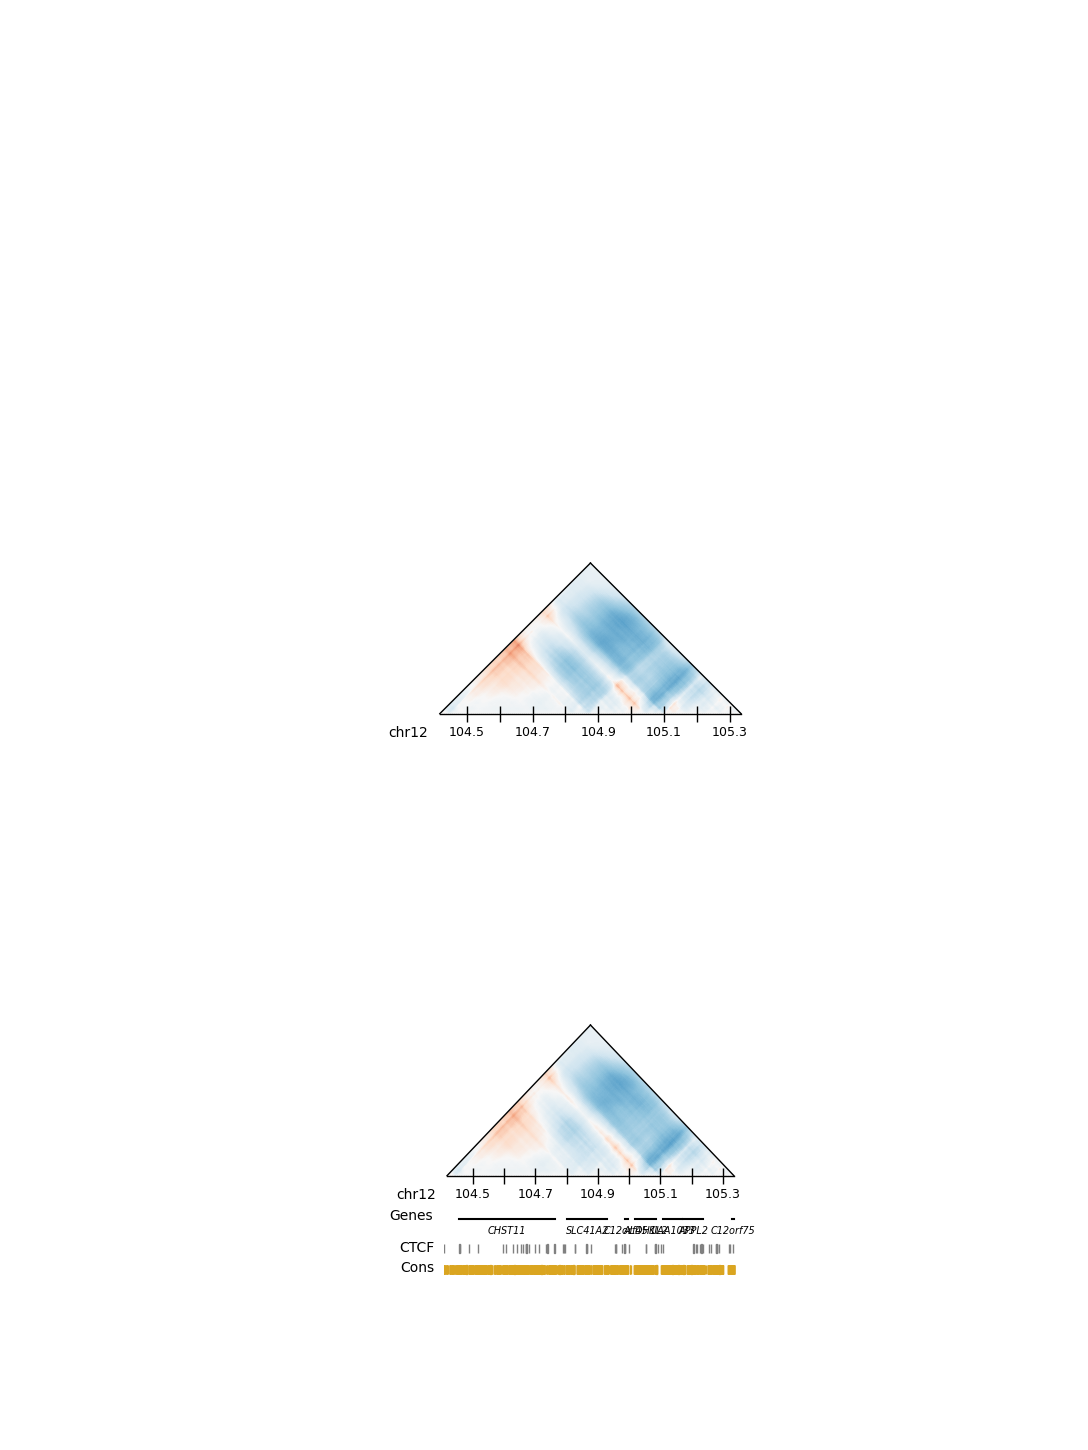

Comparisons saved.


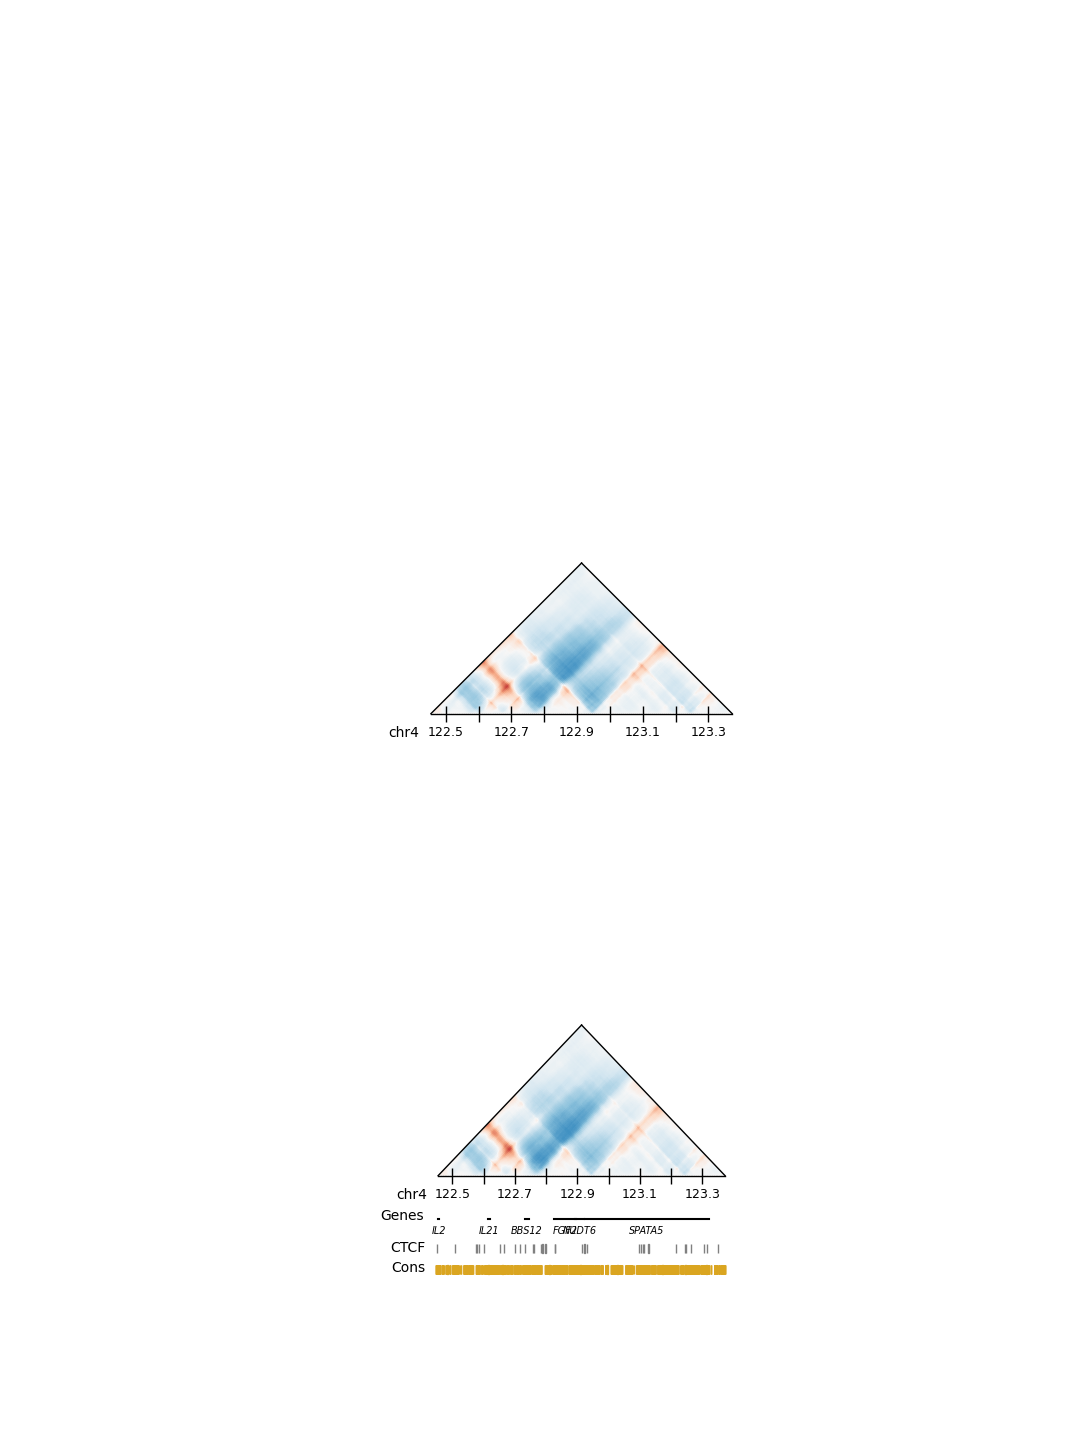

Comparisons saved.


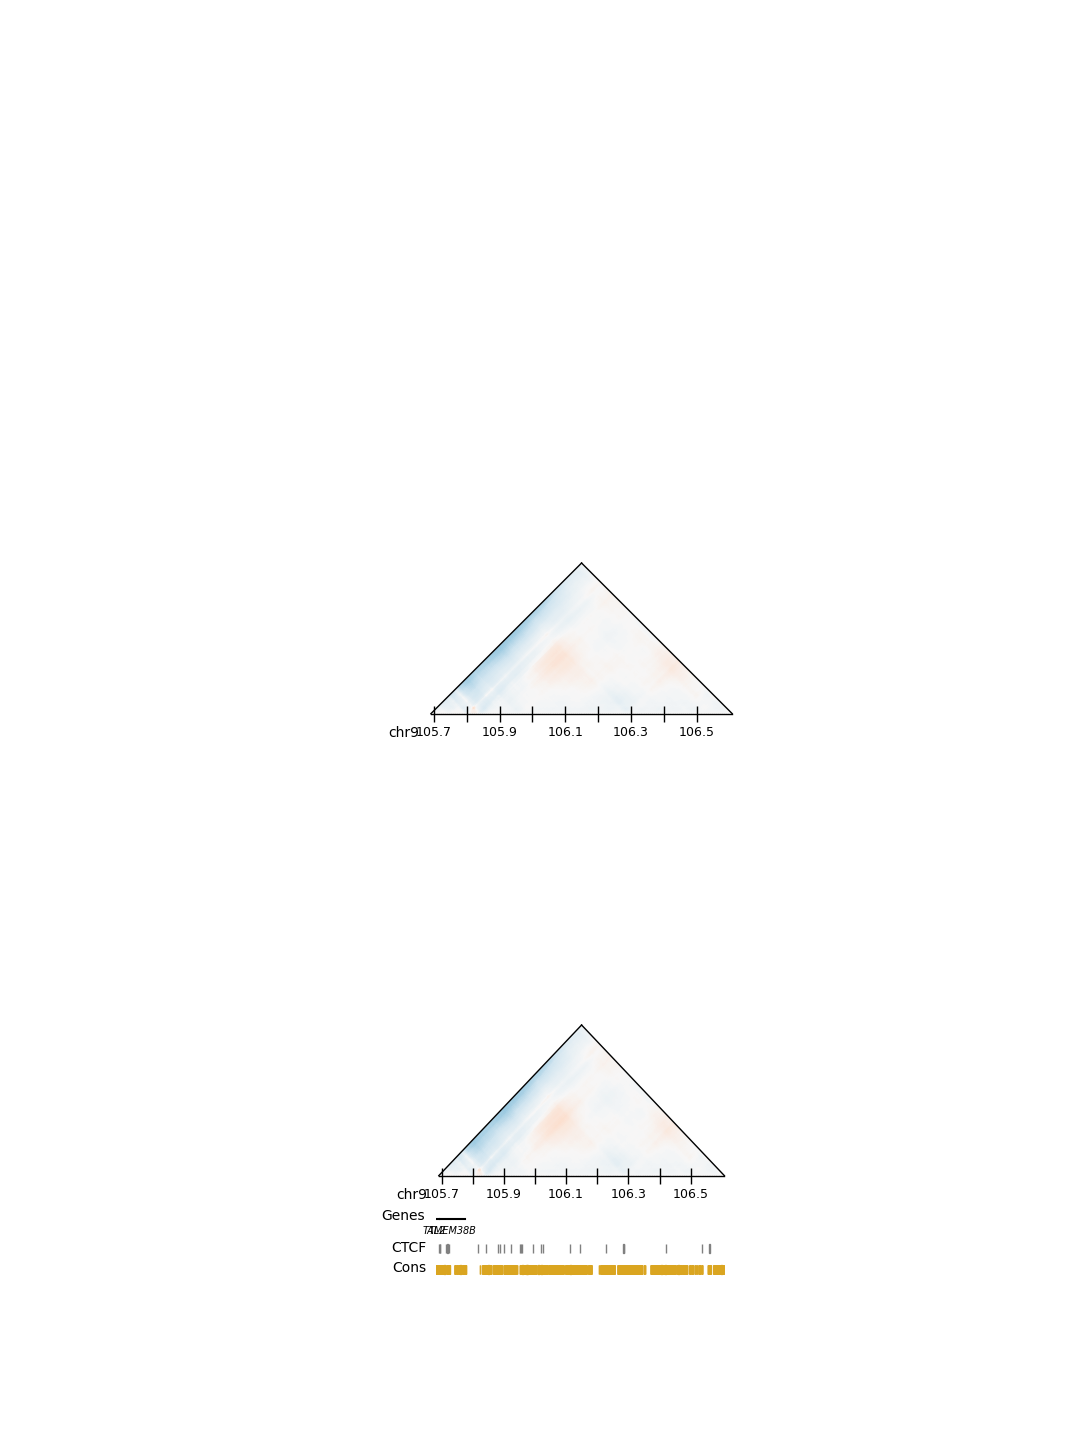

Comparisons saved.


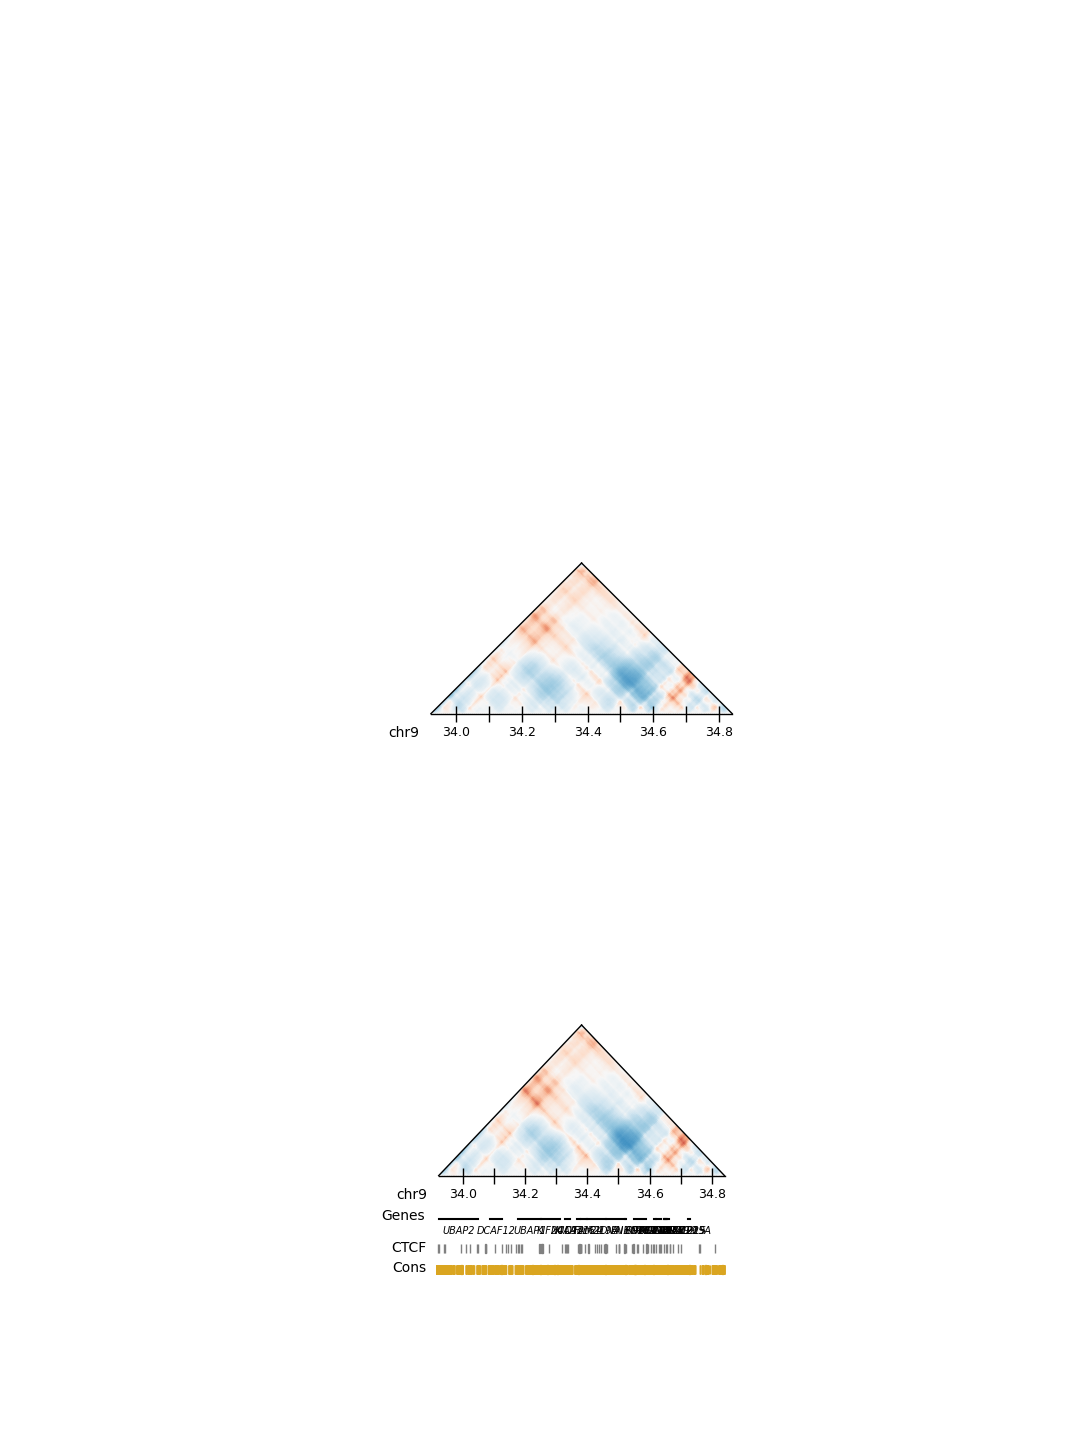

Comparisons saved.


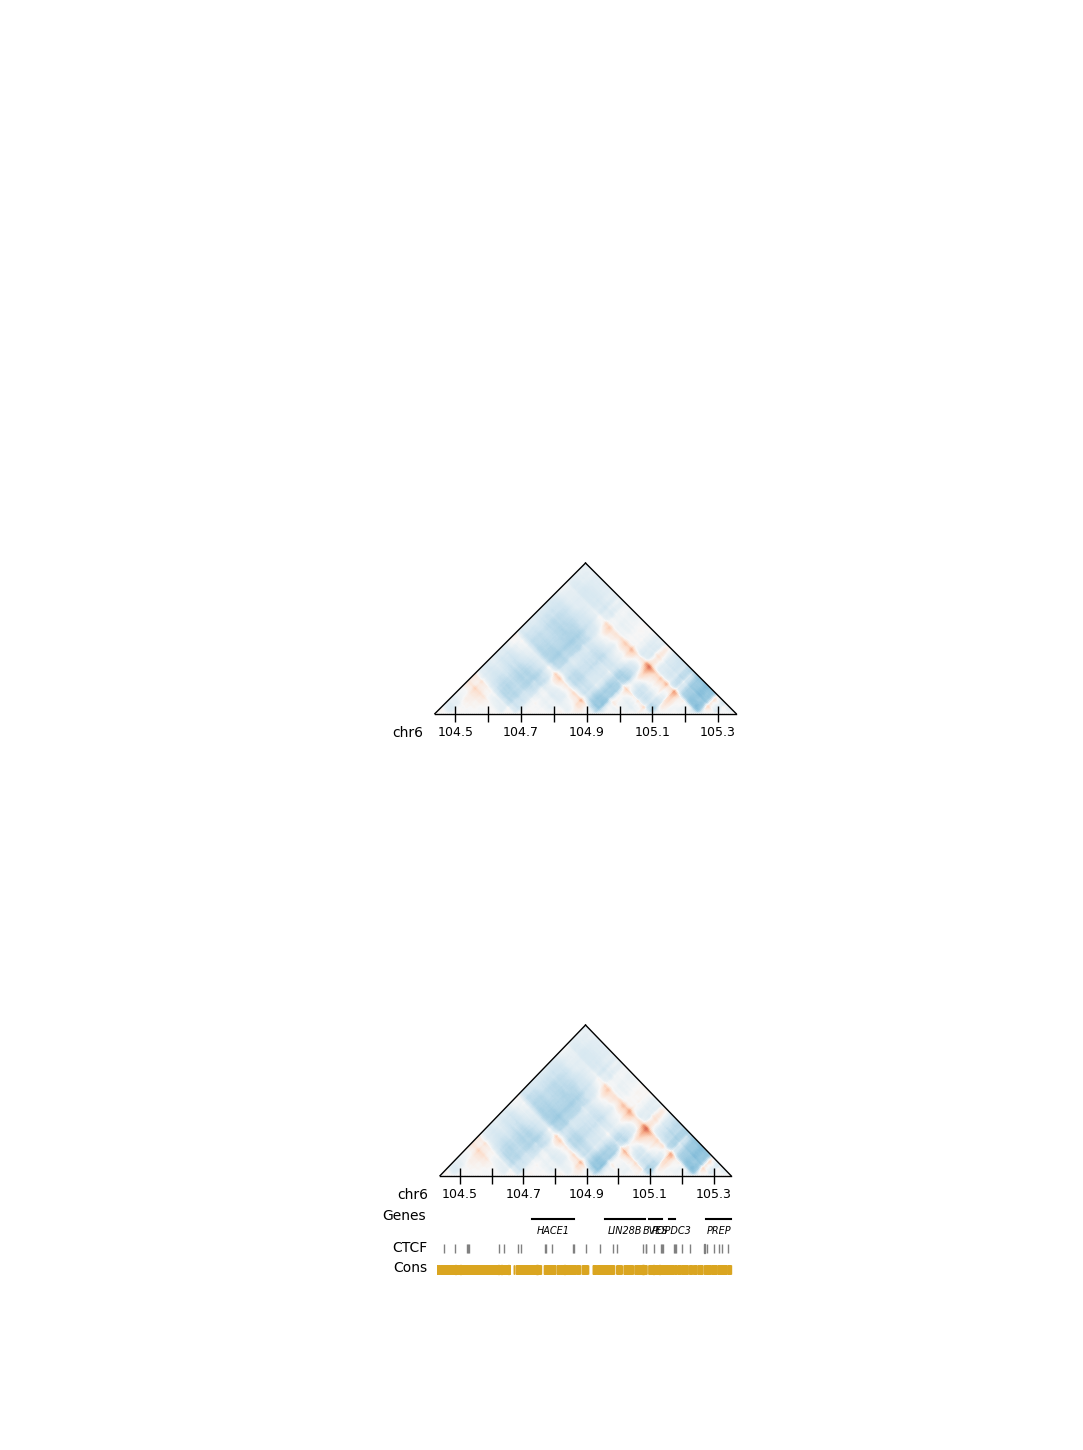

Comparisons saved.


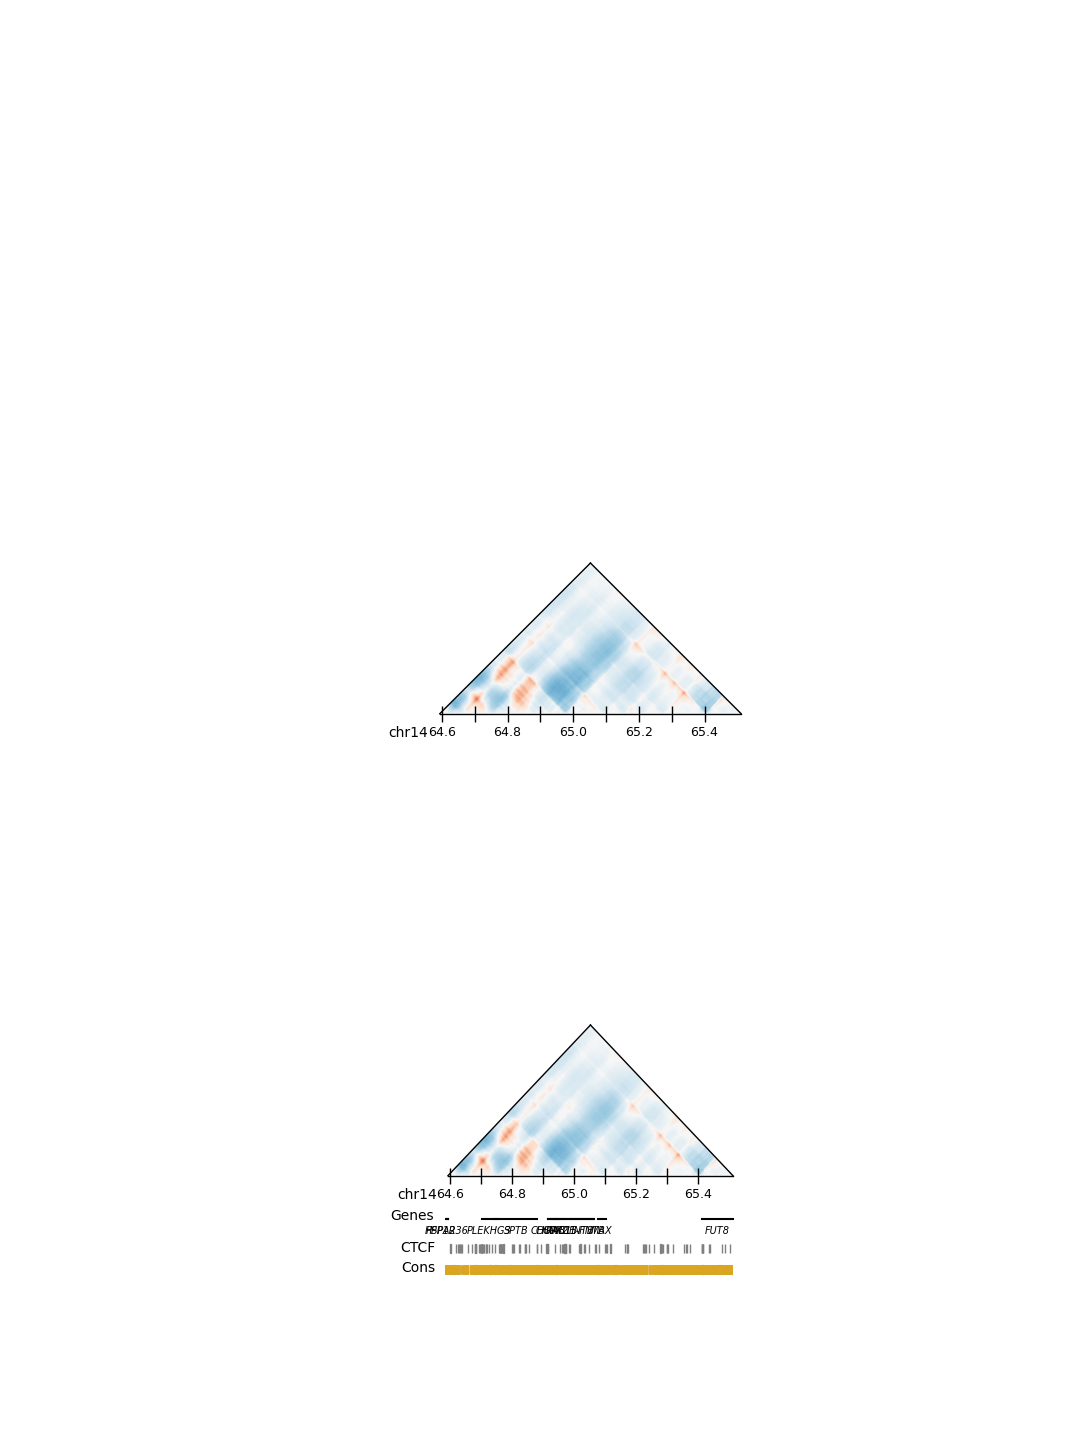

Comparisons saved.


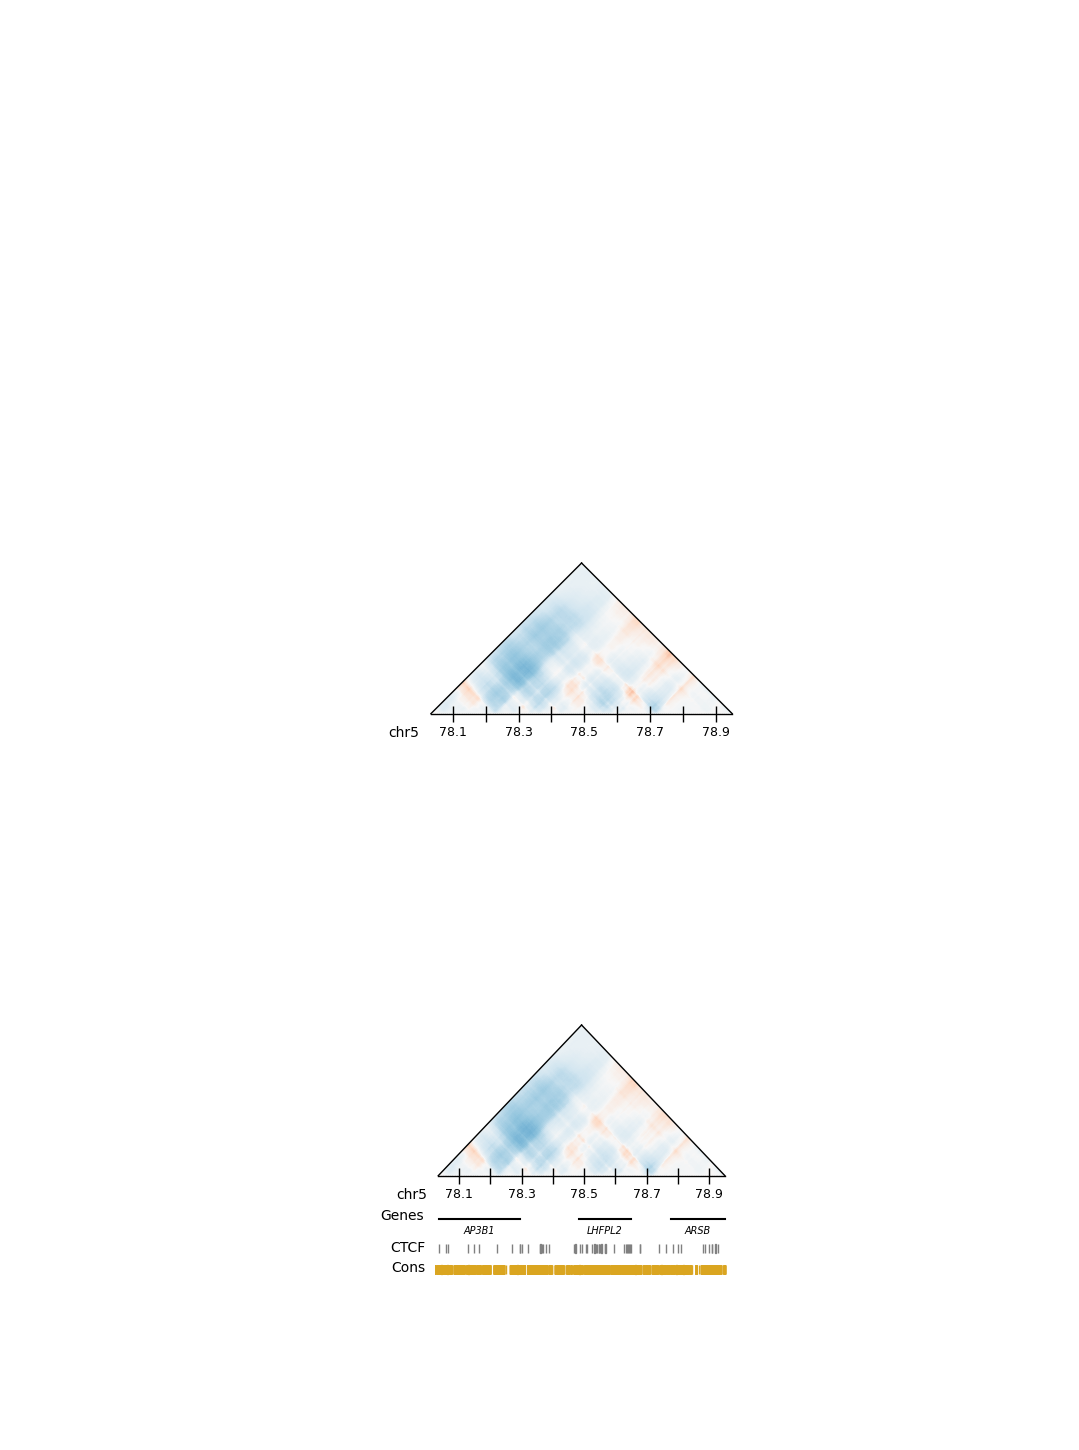

Comparisons saved.


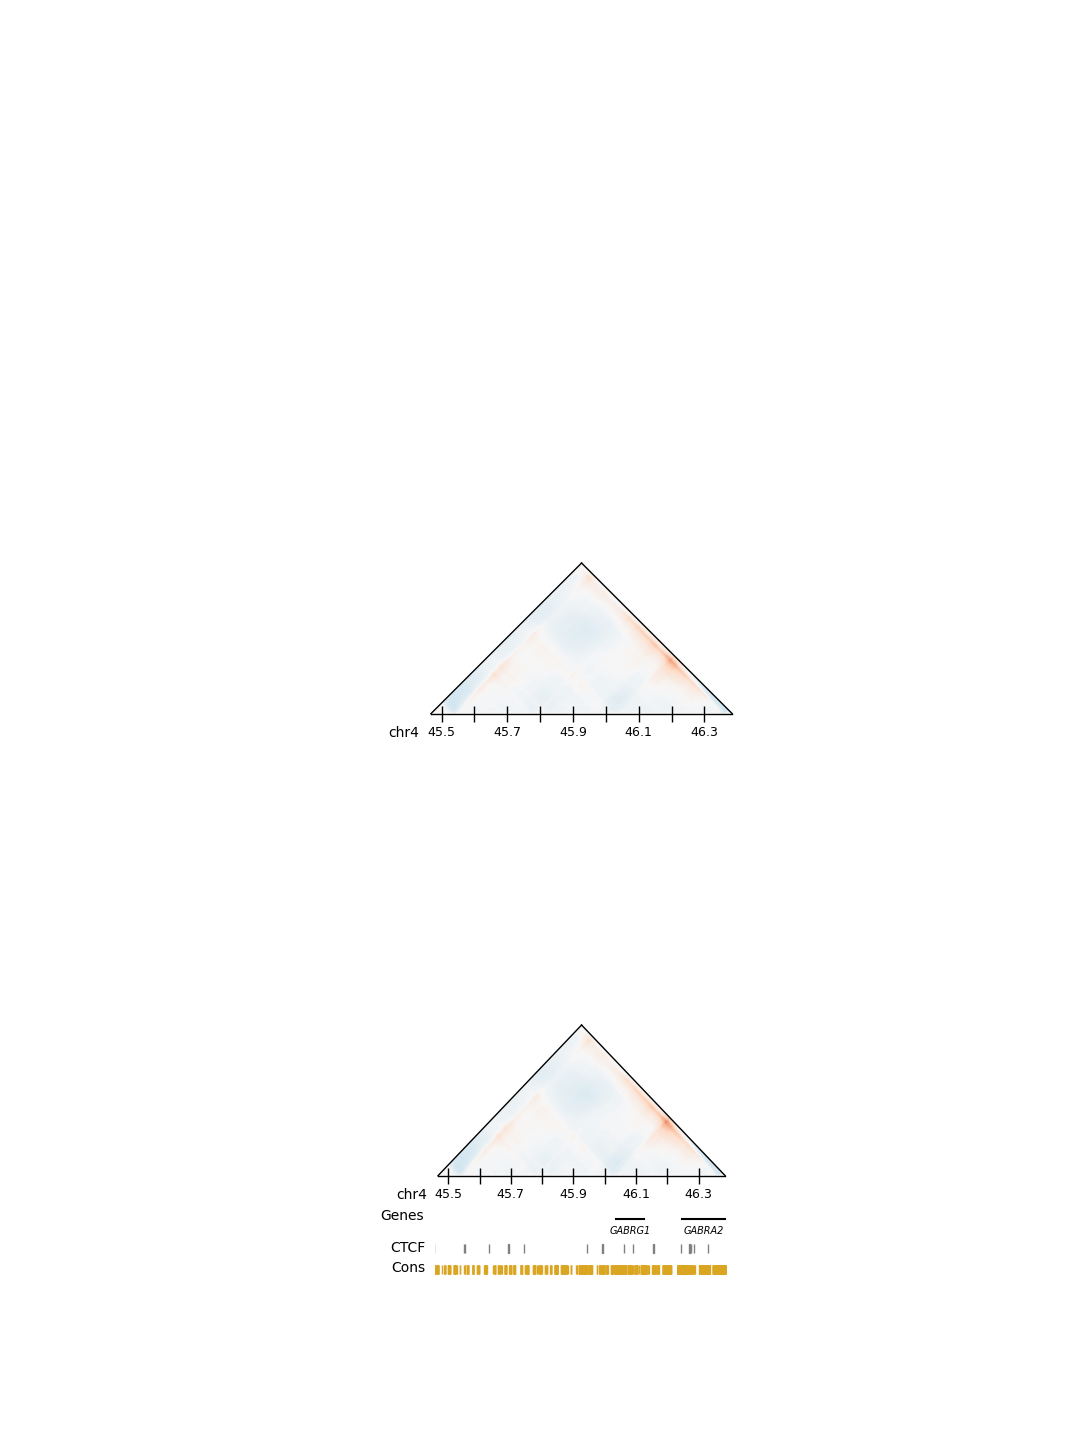

Comparisons saved.


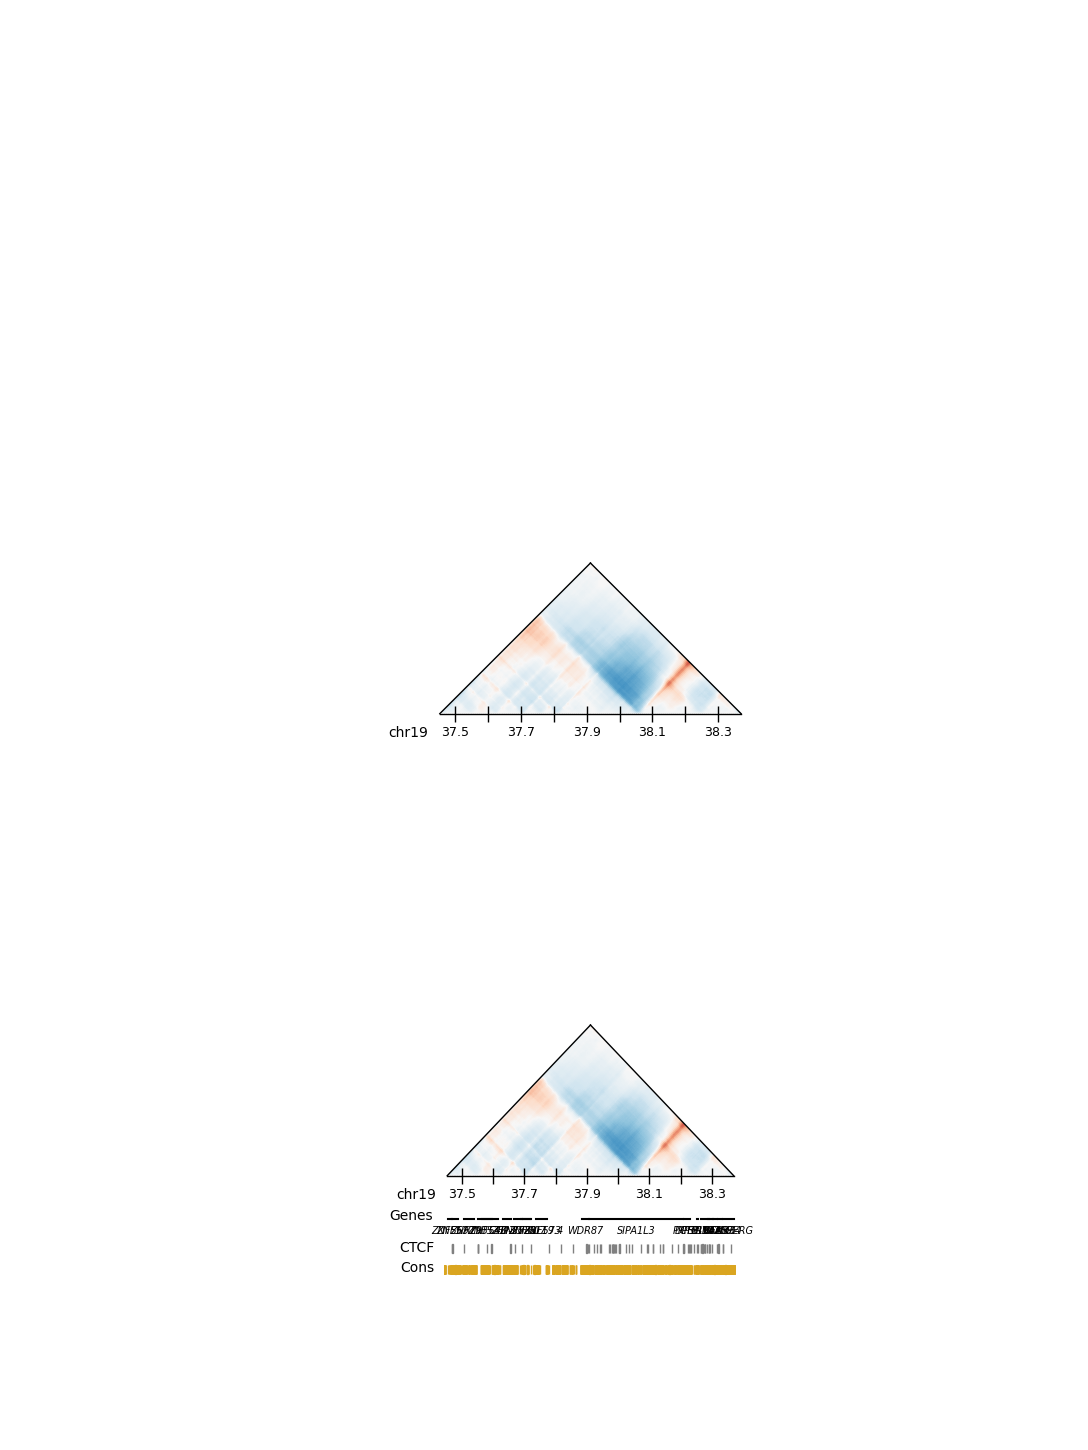

Comparisons saved.


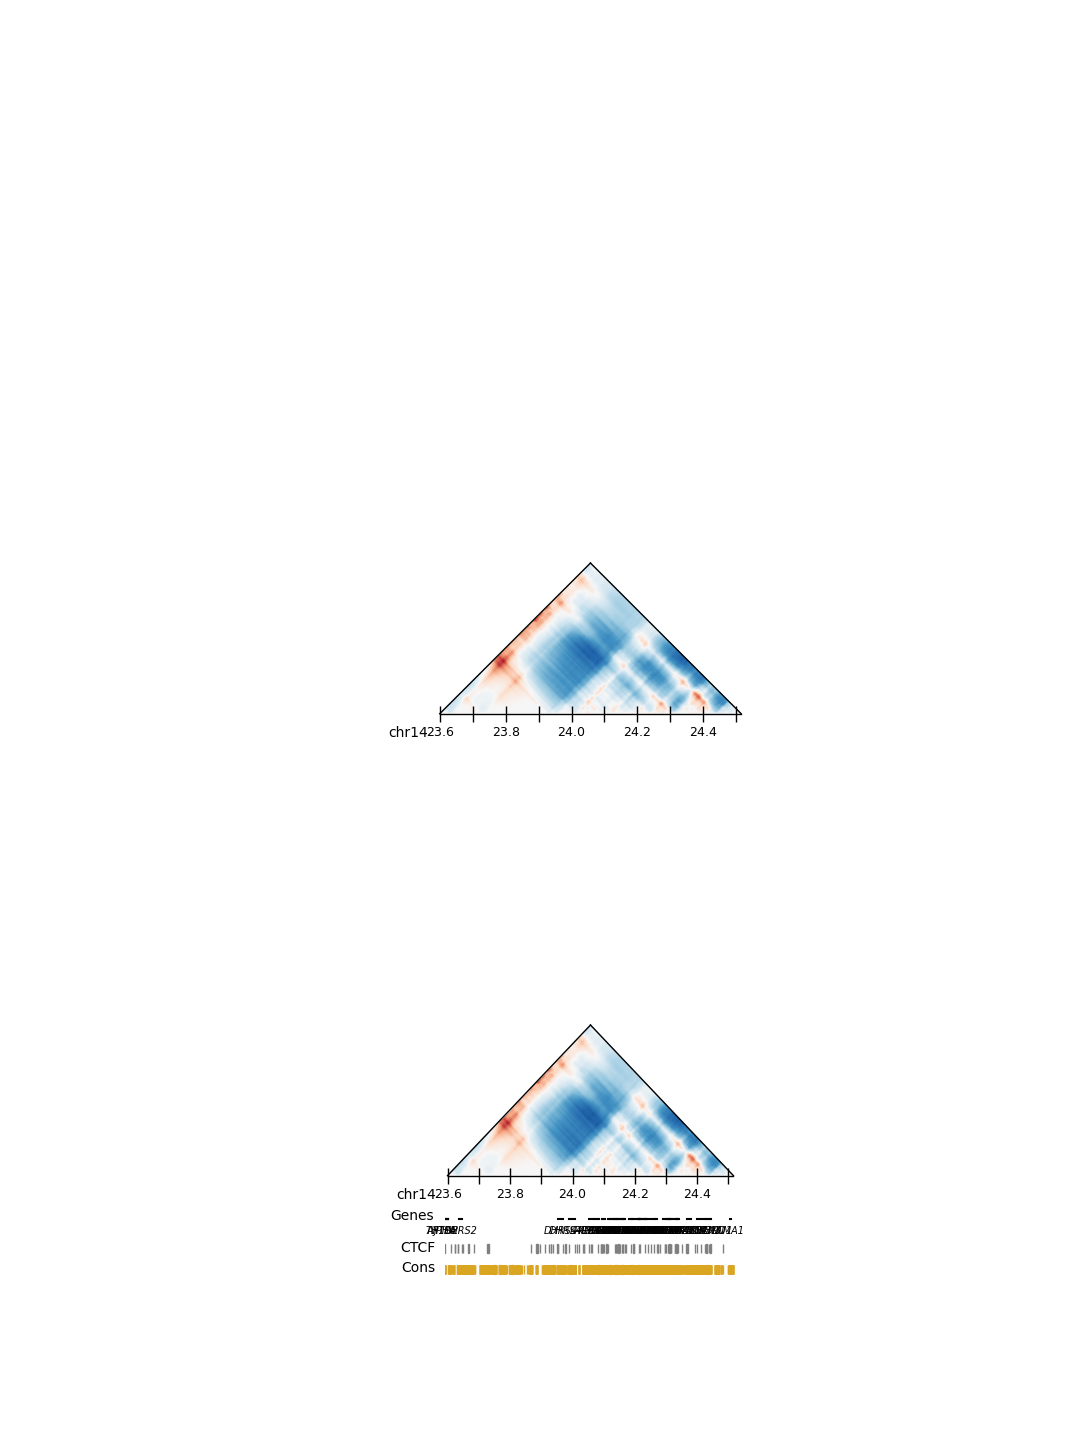

Comparisons saved.


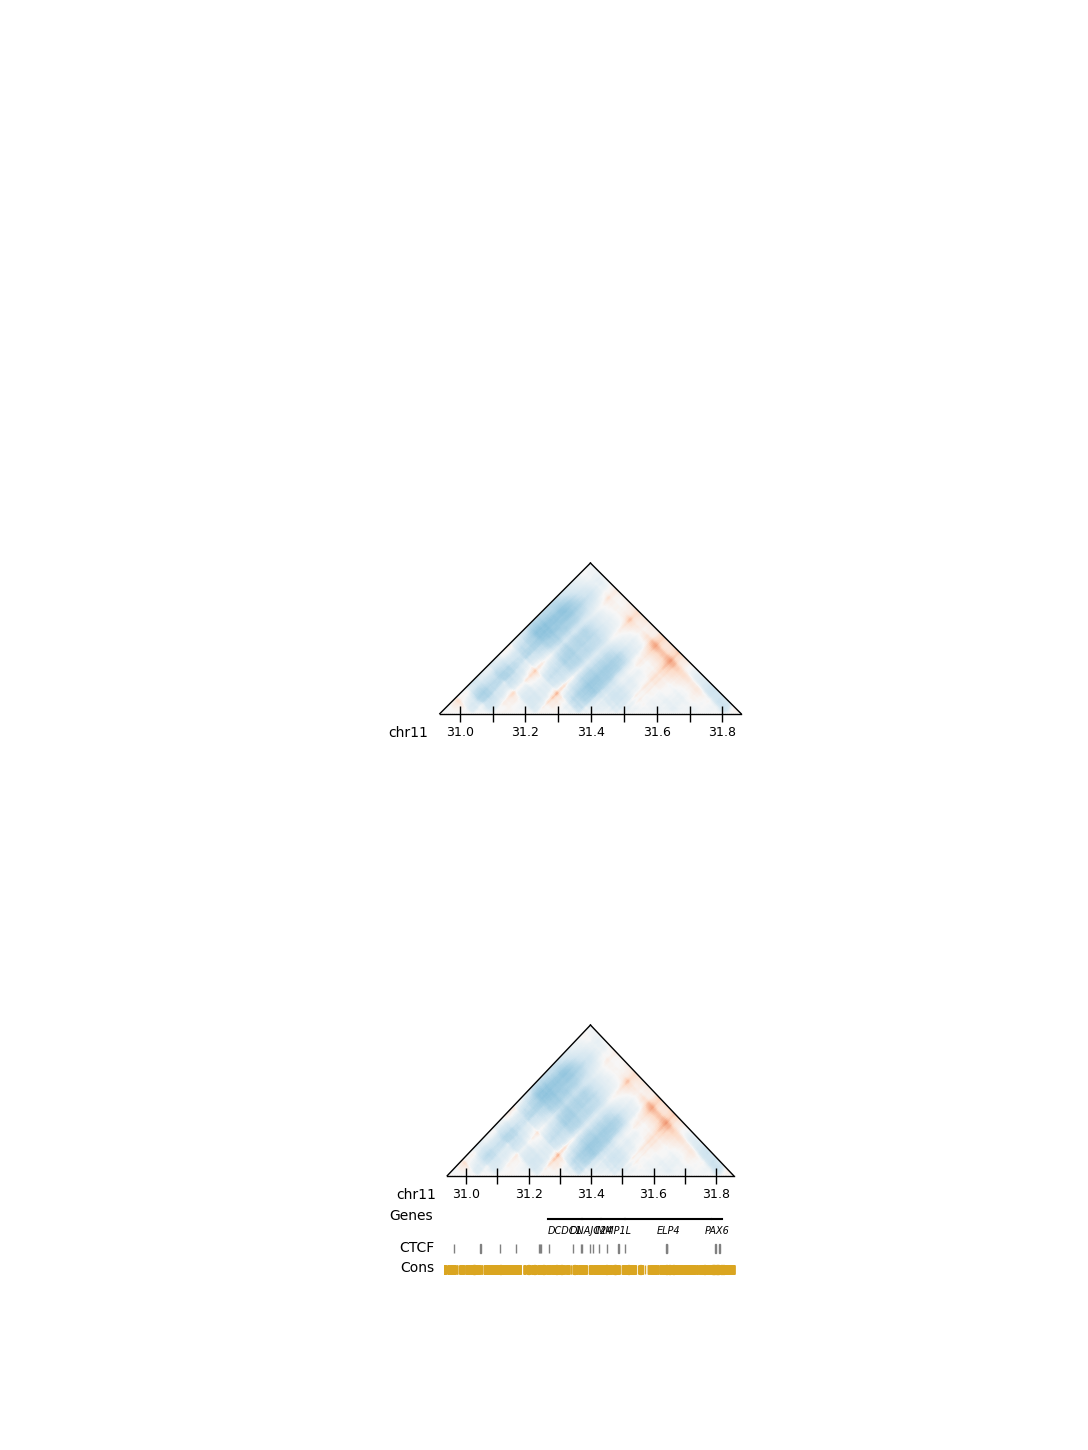

Comparisons saved.


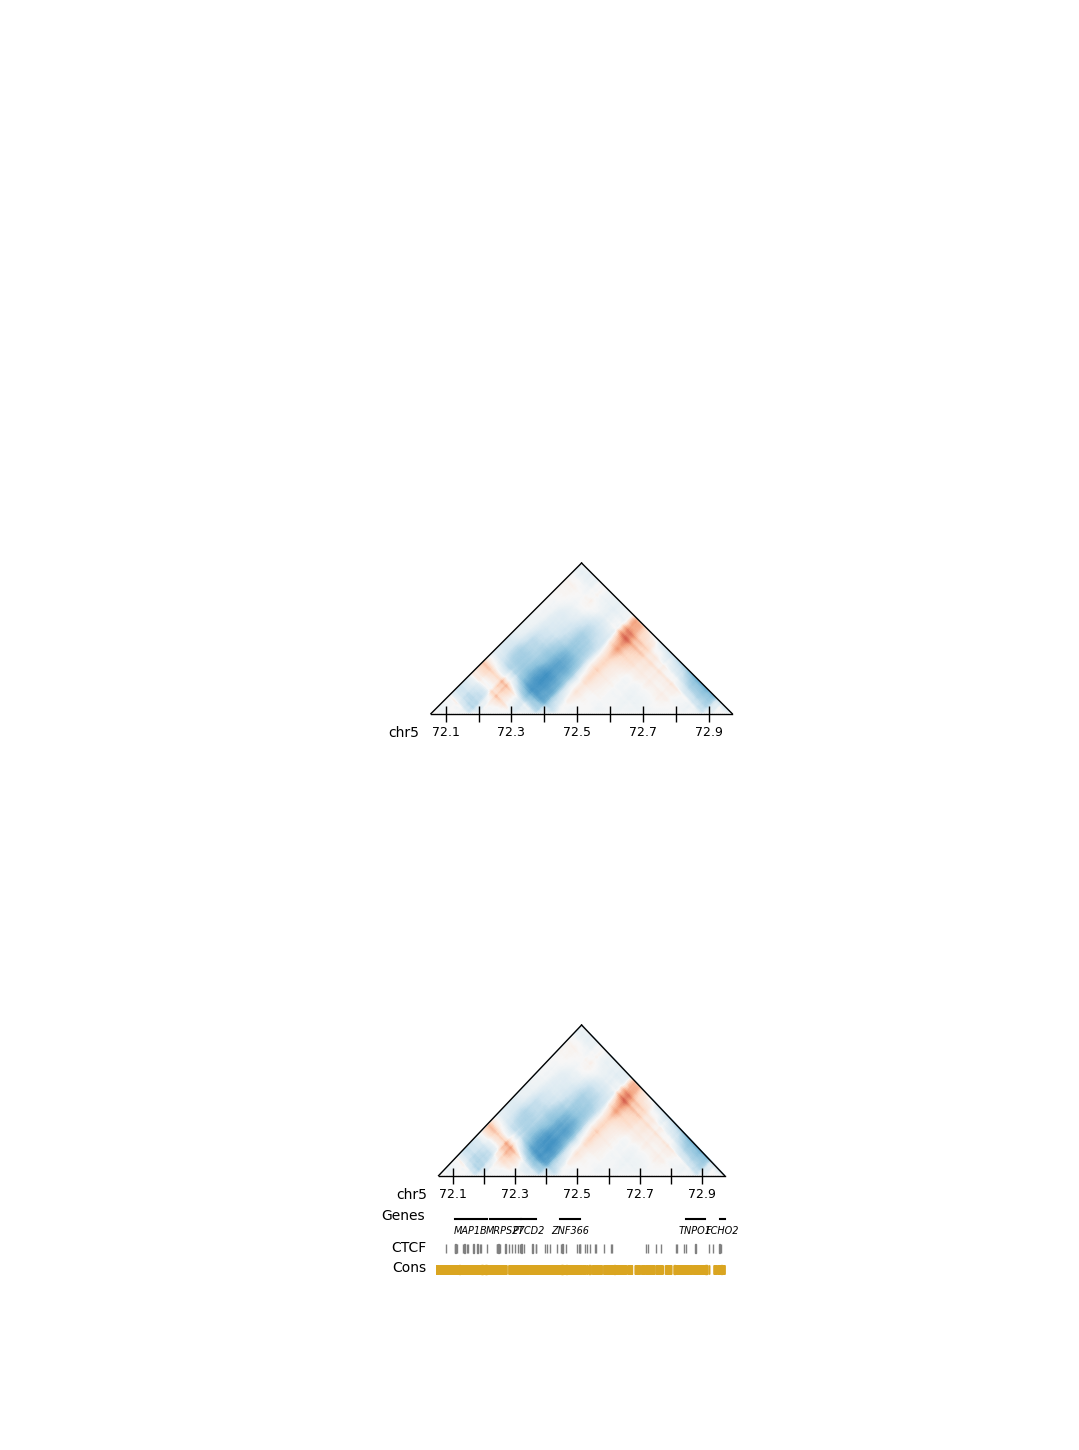

In [20]:
map_comparison_no_delta_with_annotations('/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_ALT5_EUR_10_96789820_T_C.txt',
                                         '/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_REF_EUR_10_96789820_T_C.txt',
                                         'chr10_96265532','yes', 10, 10,'chr10_96265532_TOREF.pdf')

map_comparison_no_delta_with_annotations('/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_ALT11_EUR_3_46258274_A_G.txt',
                                         '/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_REF_EUR_3_46258274_A_G.txt',
                                         'chr3_45733986','yes', 10, 10,'chr3_45733986_TOREF.pdf')

map_comparison_no_delta_with_annotations('/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_ALT11_EAS_12_104877307_G_T.txt',
                                         '/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_REF_EAS_12_104877307_G_T.txt','chr12_104353019','yes', 10, 10,'chr12_104353019_TOREF.pdf')

map_comparison_no_delta_with_annotations('/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_ALT13_EUR_4_122914501_C_A.txt',
                                         '/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_REF_EUR_4_122914501_C_A.txt',
                                         'chr4_122390213','yes', 10, 10,'chr4_122390213_TOREF.pdf')

map_comparison_no_delta_with_annotations('/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_ALT17_EUR_9_106150630_A_G.txt',
                                         '/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_REF_EUR_9_106150630_A_G.txt',
                                         'chr9_105626342','yes', 10, 10,'chr9_105626342_TOREF.pdf')

map_comparison_no_delta_with_annotations('/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_ALT10_EUR_9_34382728_A_G.txt',
                                         '/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_REF_EUR_9_34382728_A_G.txt',
                                         'chr9_33858440','yes', 10, 10,'chr9_33858440_TOREF.pdf')

map_comparison_no_delta_with_annotations('/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_ALT2_EUR_6_104897150_T_C.txt',
                                         '/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_REF_EUR_6_104897150_T_C.txt',
                                         'chr6_104372862','yes', 10, 10,'chr6_104372862_TOREF.pdf')

map_comparison_no_delta_with_annotations('/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_ALT5_EUR_14_65053528_T_C.txt',
                                         '/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_REF_EUR_14_65053528_T_C.txt',
                                         'chr14_64529240','yes', 10, 10,'chr14_64529240_TOREF.pdf')

map_comparison_no_delta_with_annotations('/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_ALT7_EAS_5_78493049_G_C.txt',
                                         '/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_REF_EAS_5_78493049_G_C.txt',
                                         'chr5_77968761','yes', 10, 10,'chr5_77968761_TOREF.pdf')

map_comparison_no_delta_with_annotations('/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_ALT5_EUR_4_45927155_A_G.txt',
                                         '/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_REF_EUR_4_45927155_A_G.txt',
                                         'chr4_45402867','yes', 10, 10,'chr4_45402867_TOREF.pdf')

map_comparison_no_delta_with_annotations('/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_ALT6_EUR_19_37912459_T_C.txt',
                                         '/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_REF_EUR_19_37912459_T_C.txt',
                                         'chr19_37388171','yes', 10, 10,'chr19_37388171_TOREF.pdf')

map_comparison_no_delta_with_annotations('/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_ALT7_EUR_14_24058463_G_A.txt',
                                         '/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_REF_EUR_14_24058463_G_A.txt',
                                         'chr14_23534175','yes', 10, 10,'chr14_23534175_TOREF.pdf')

map_comparison_no_delta_with_annotations('/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_ALT12_EUR_11_31399033_G_A.txt',
                                         '/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_REF_EUR_11_31399033_G_A.txt',
                                         'chr11_30874745','yes', 10, 10,'chr11_30874745_TOREF.pdf')

map_comparison_no_delta_with_annotations('/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_ALT1_EUR_5_72514419_G_A.txt',
                                         '/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_REF_EUR_5_72514419_G_A.txt',
                                         'chr5_71990131','yes', 10, 10,'chr5_71990131_TOREF.pdf')


Comparisons saved.


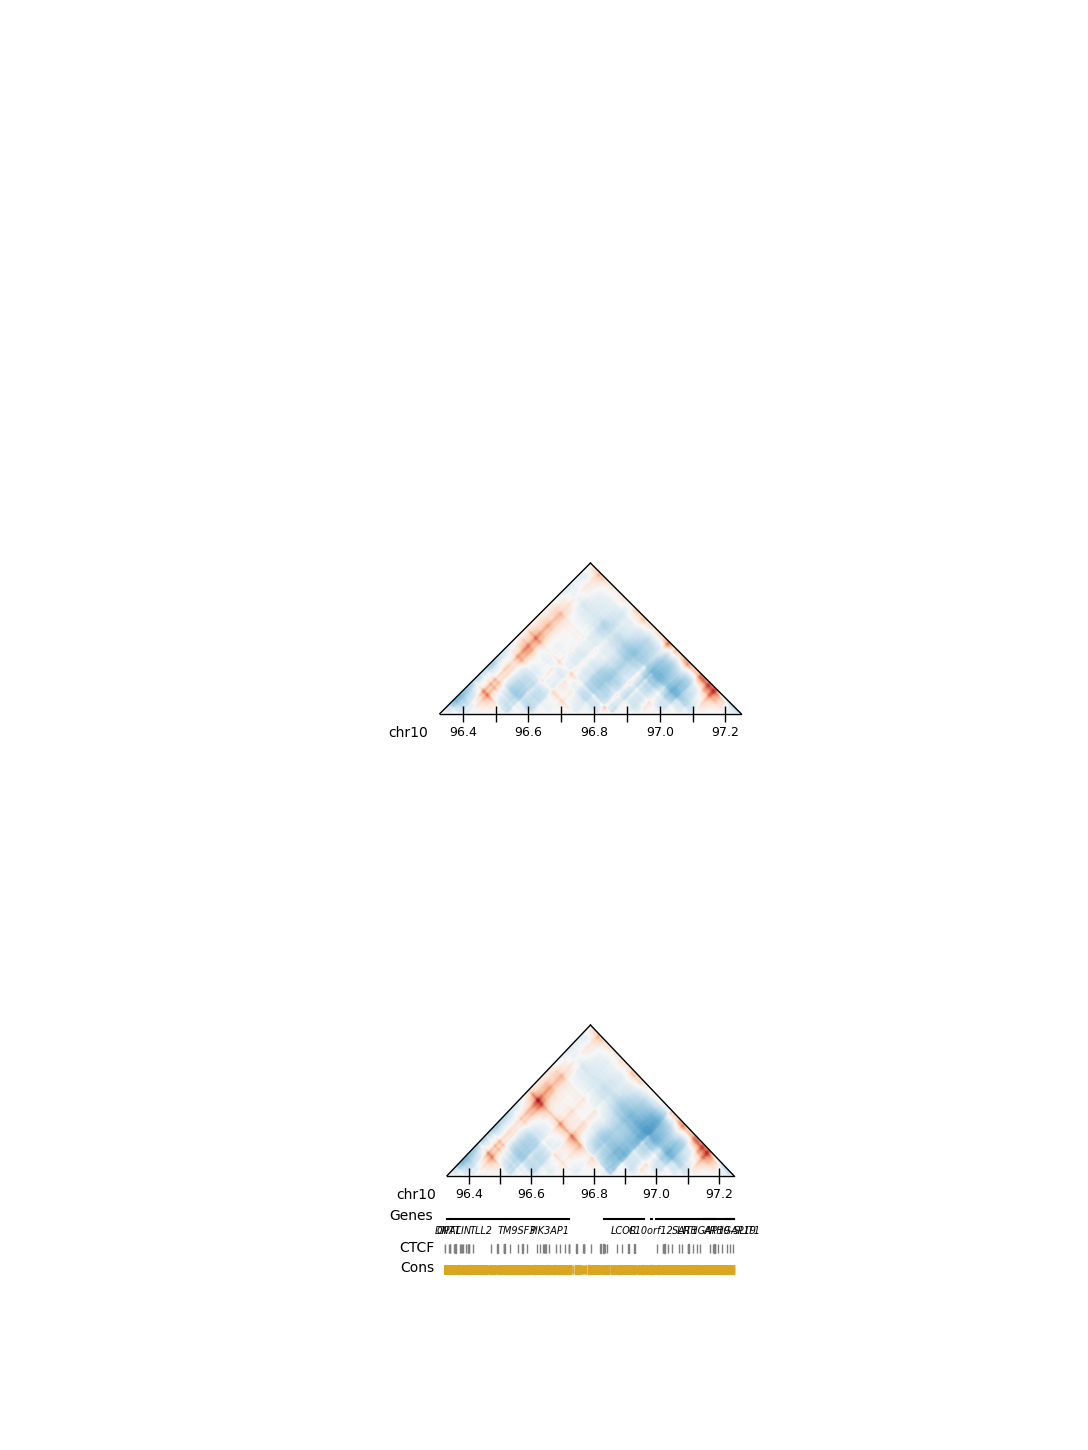

Comparisons saved.


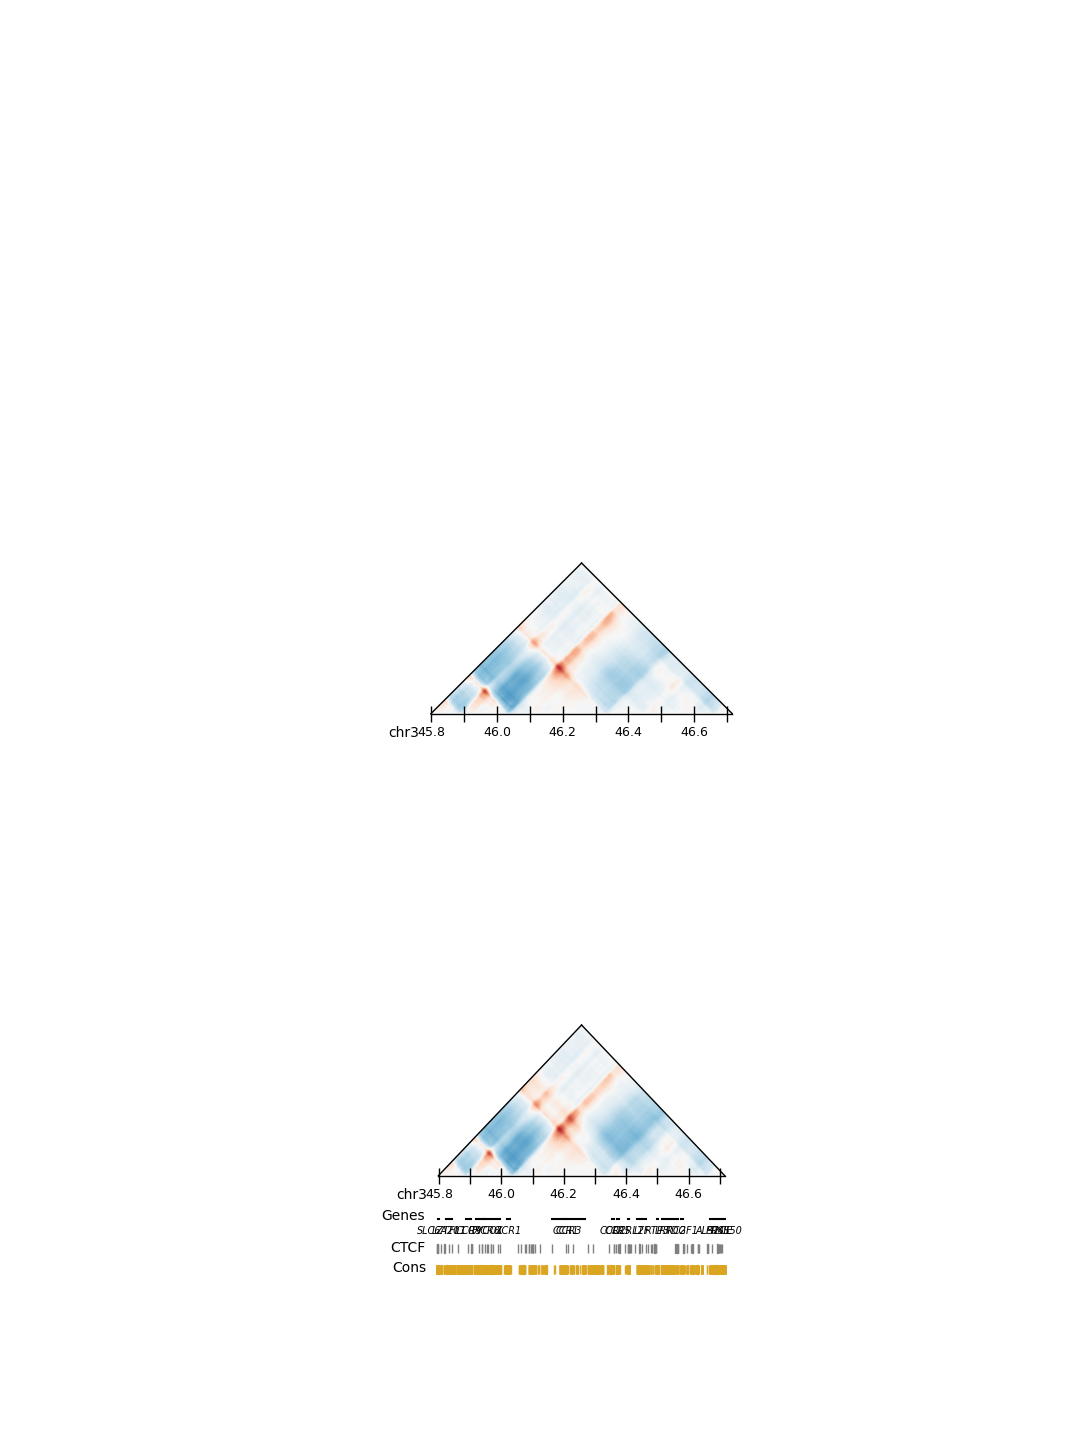

Comparisons saved.


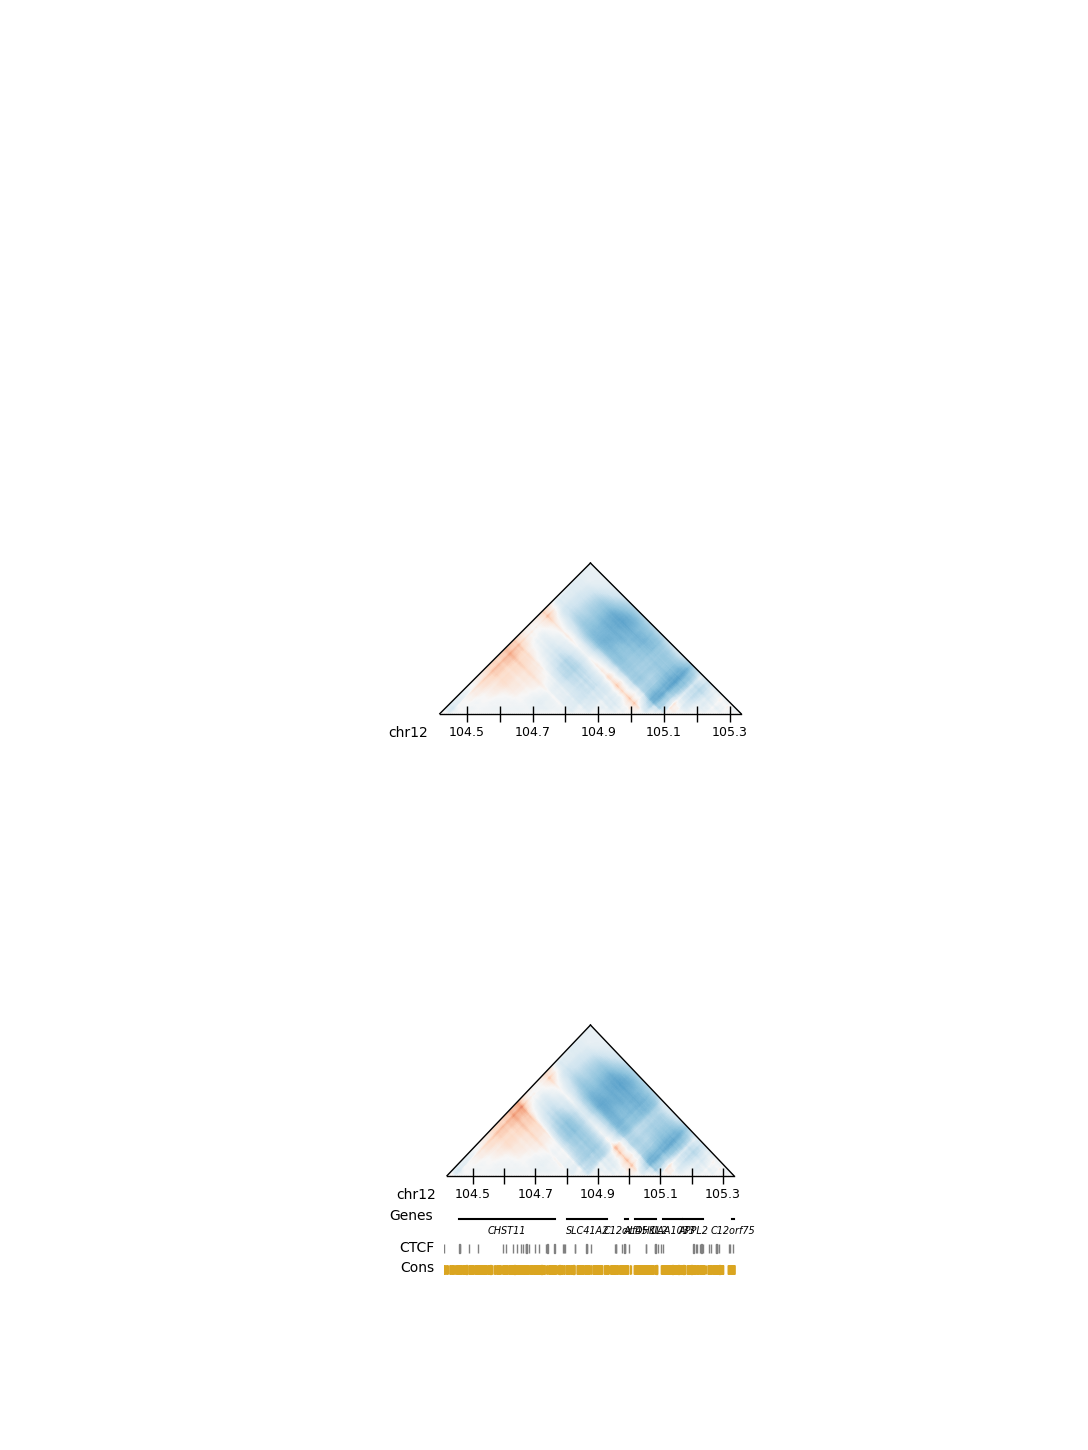

Comparisons saved.


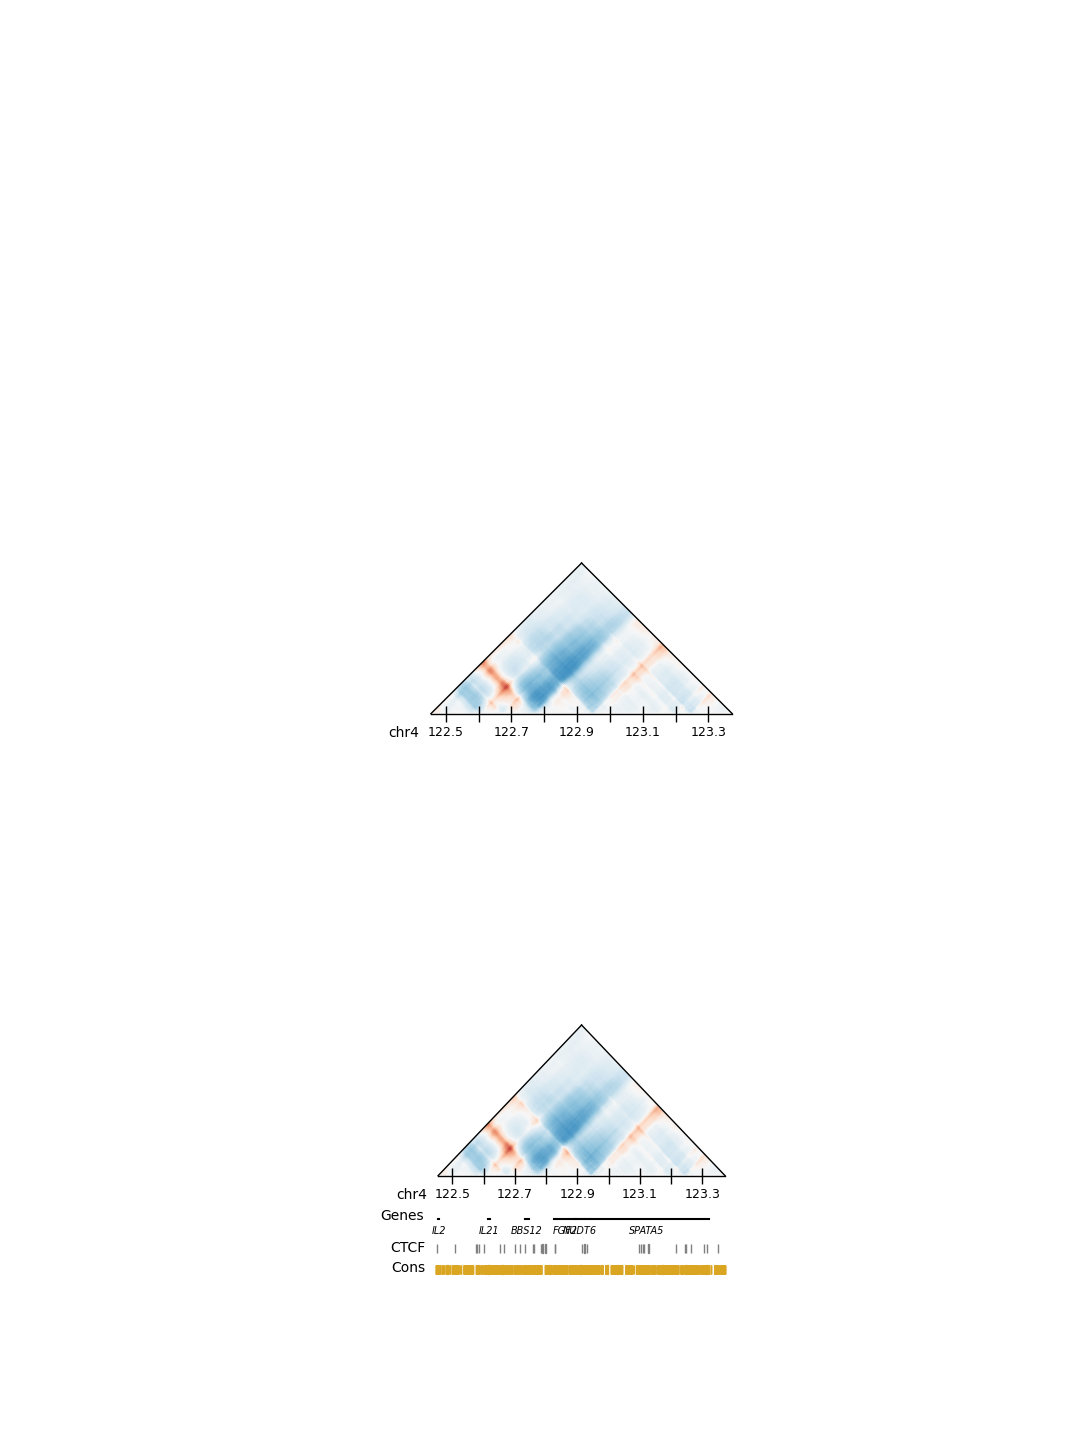

Comparisons saved.


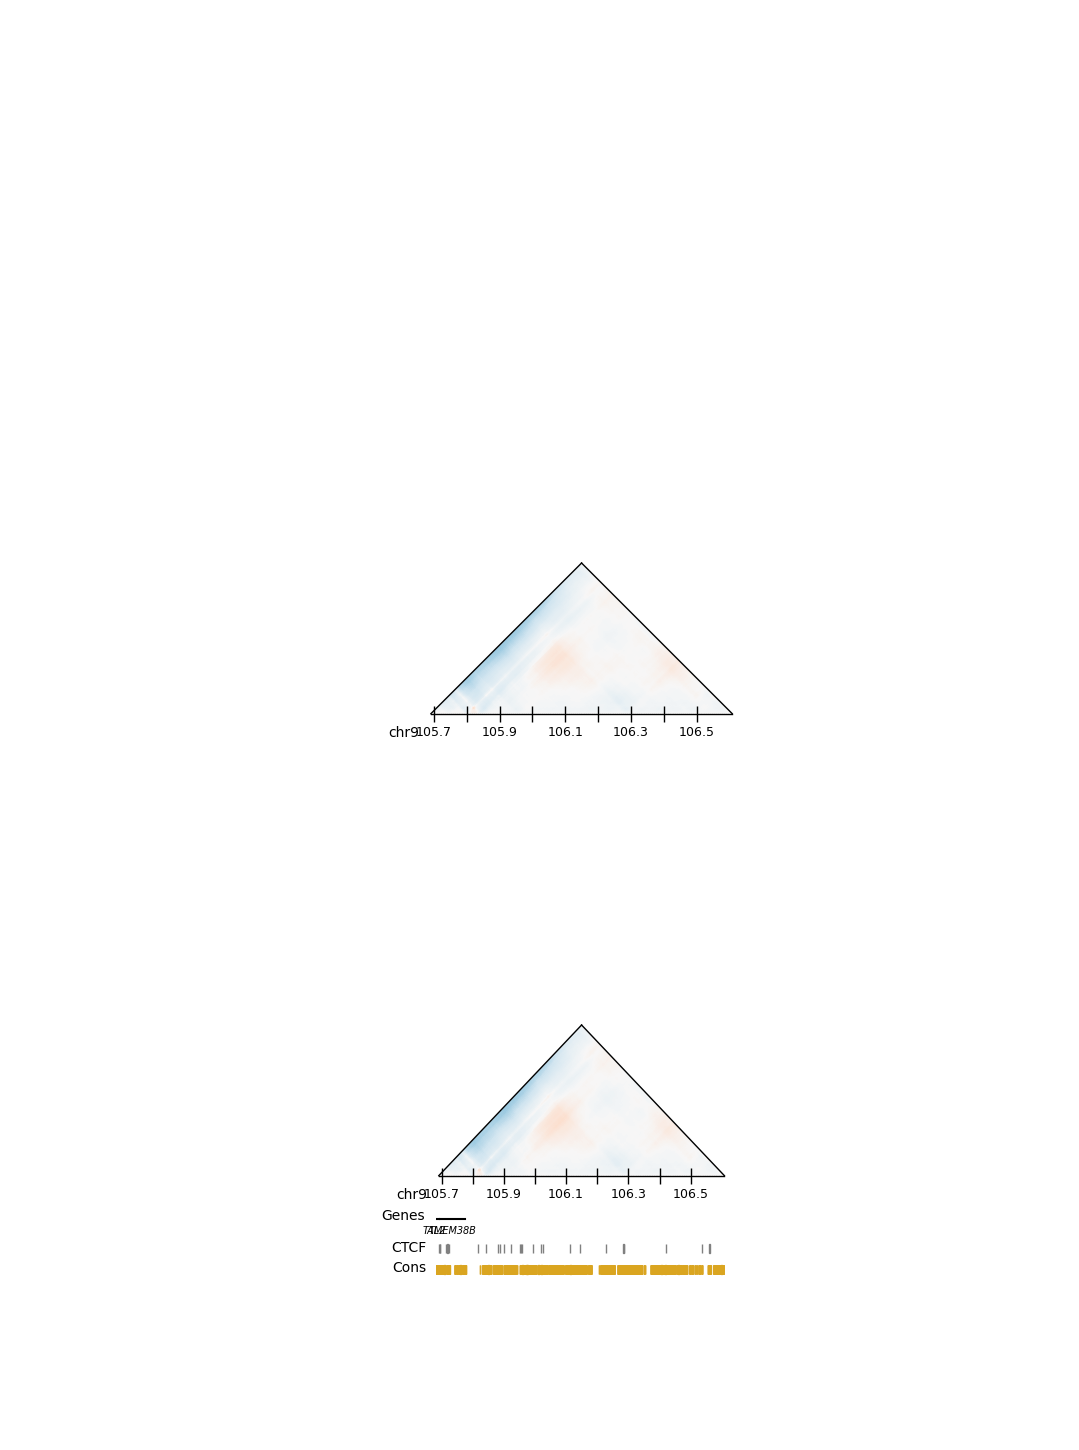

Comparisons saved.


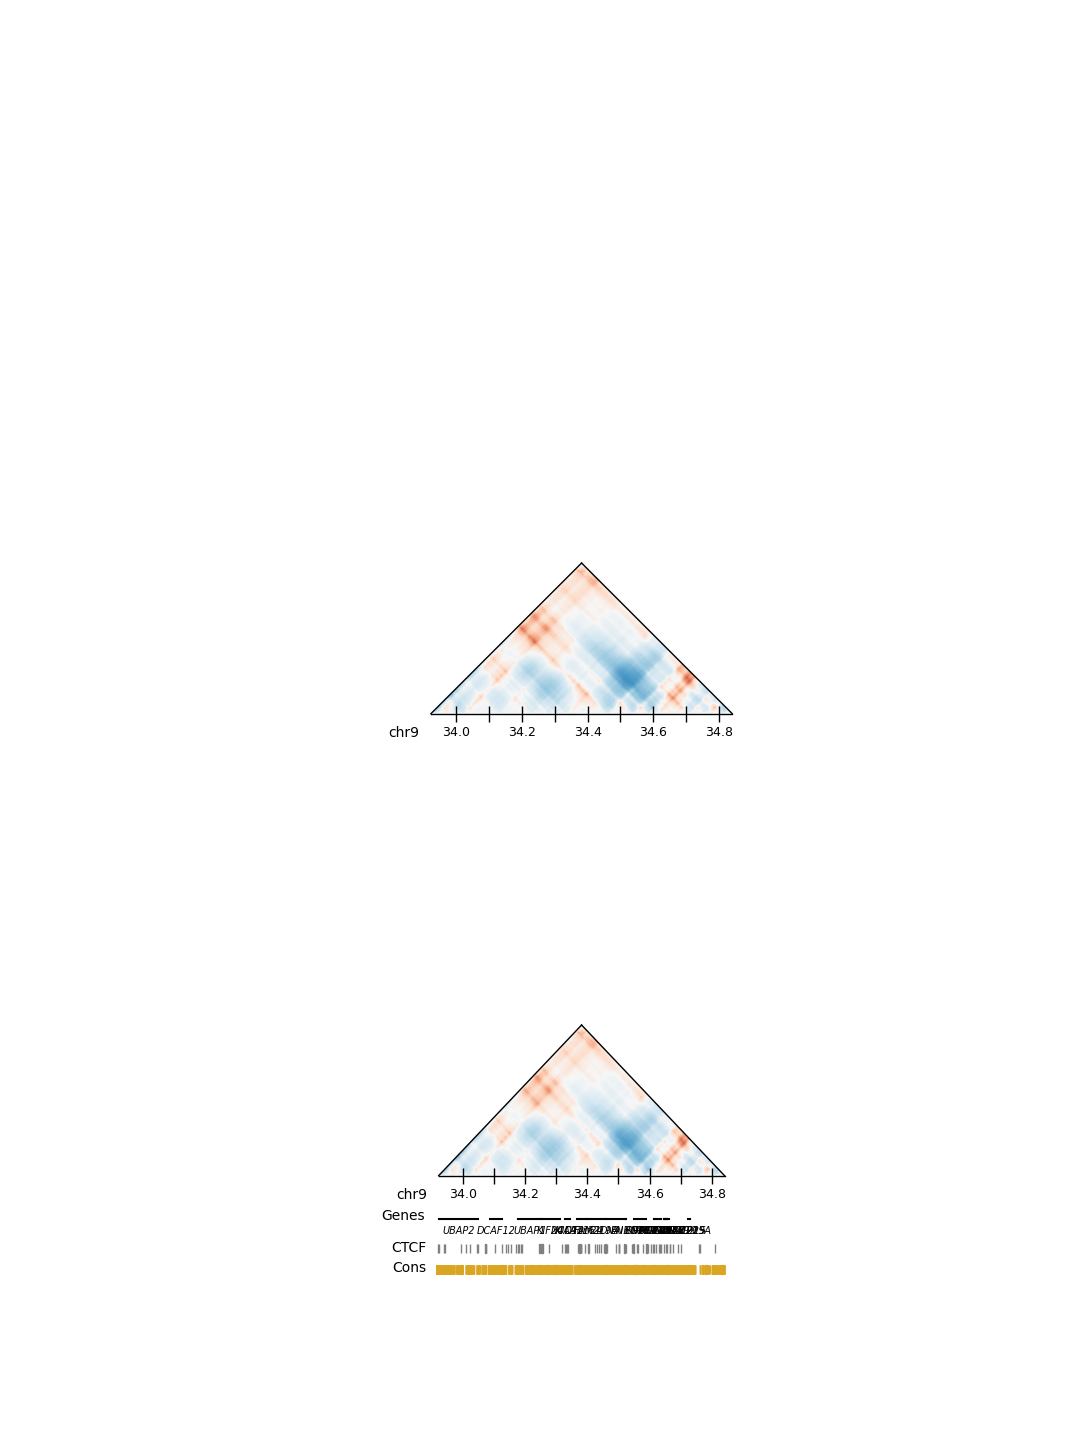

Comparisons saved.


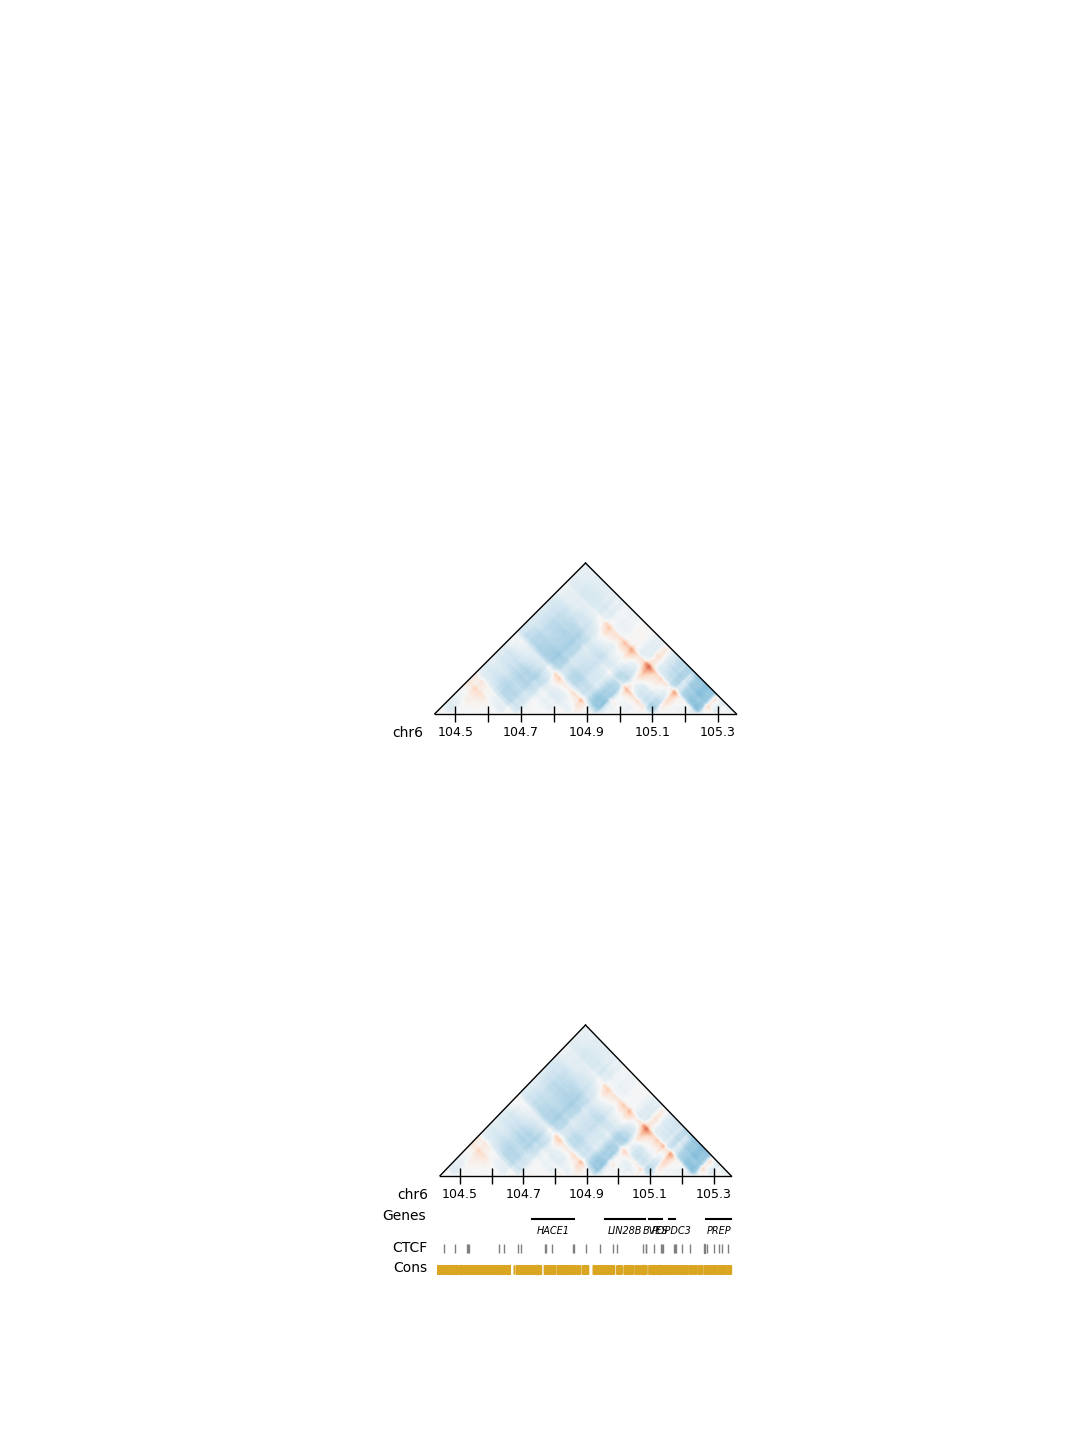

Comparisons saved.


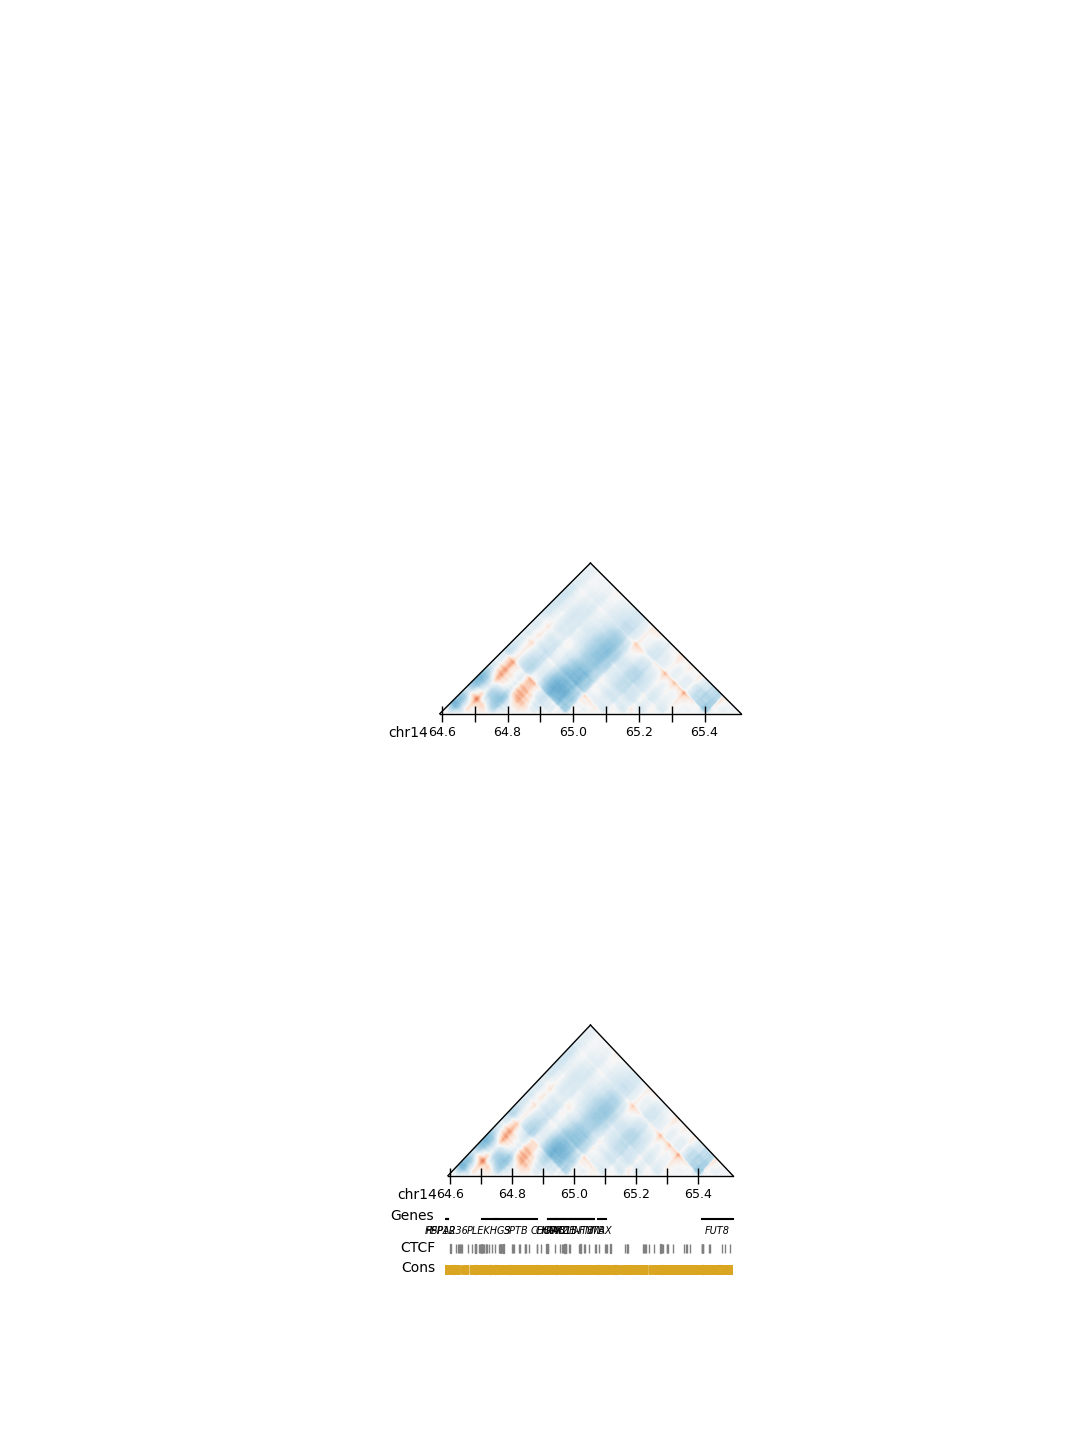

Comparisons saved.


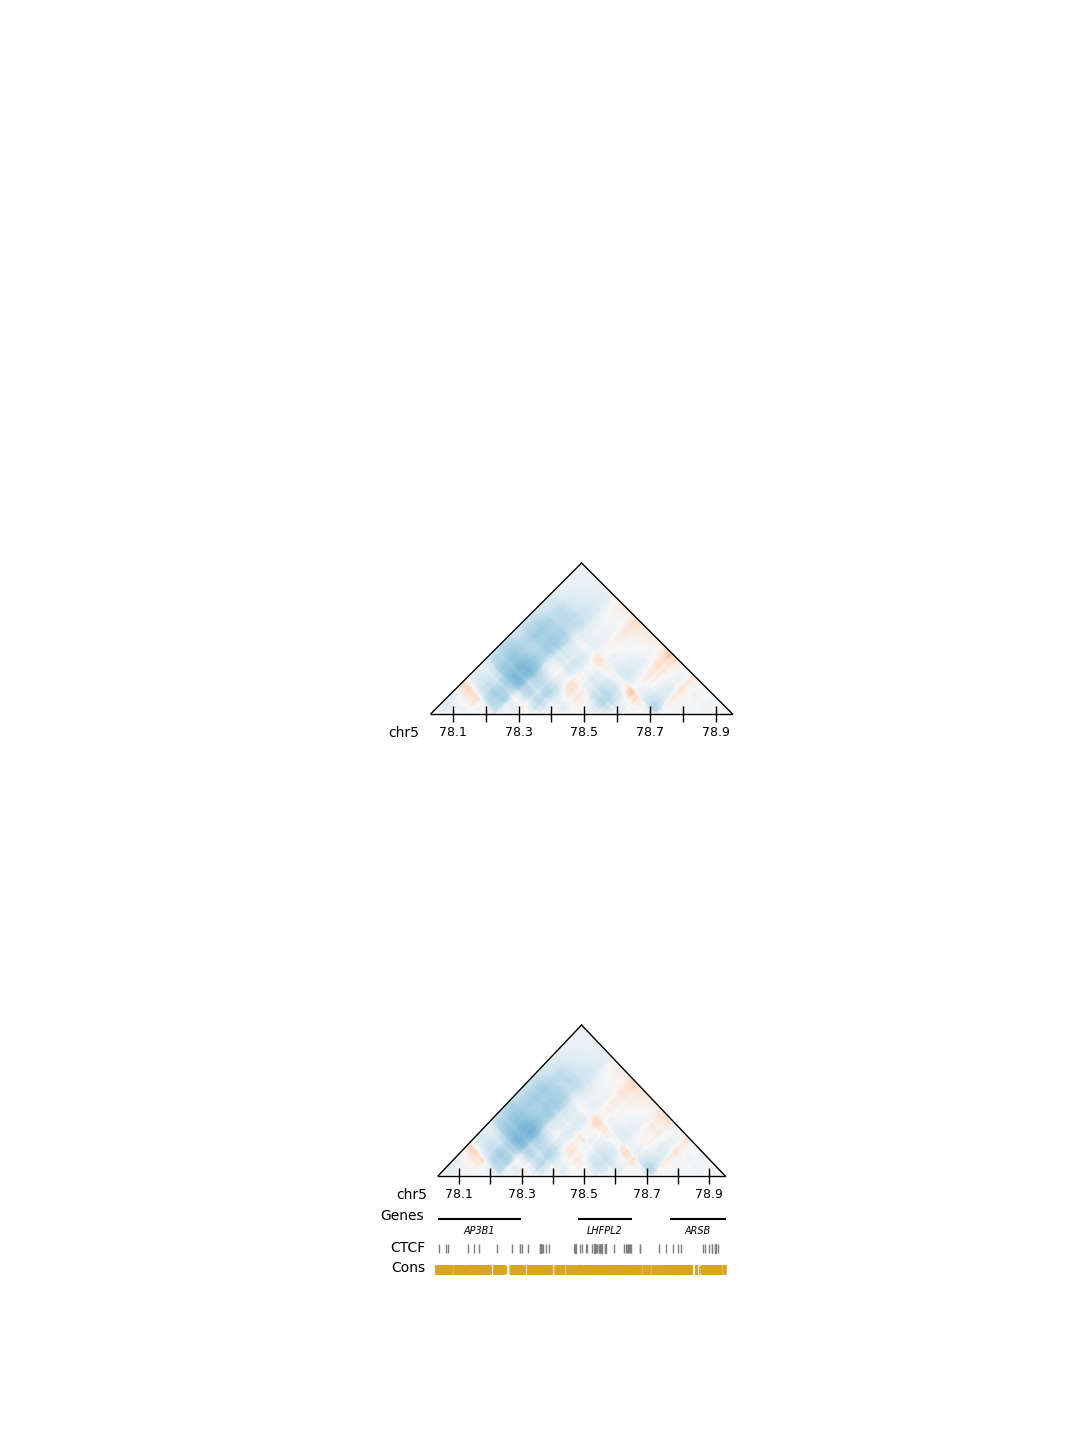

Comparisons saved.


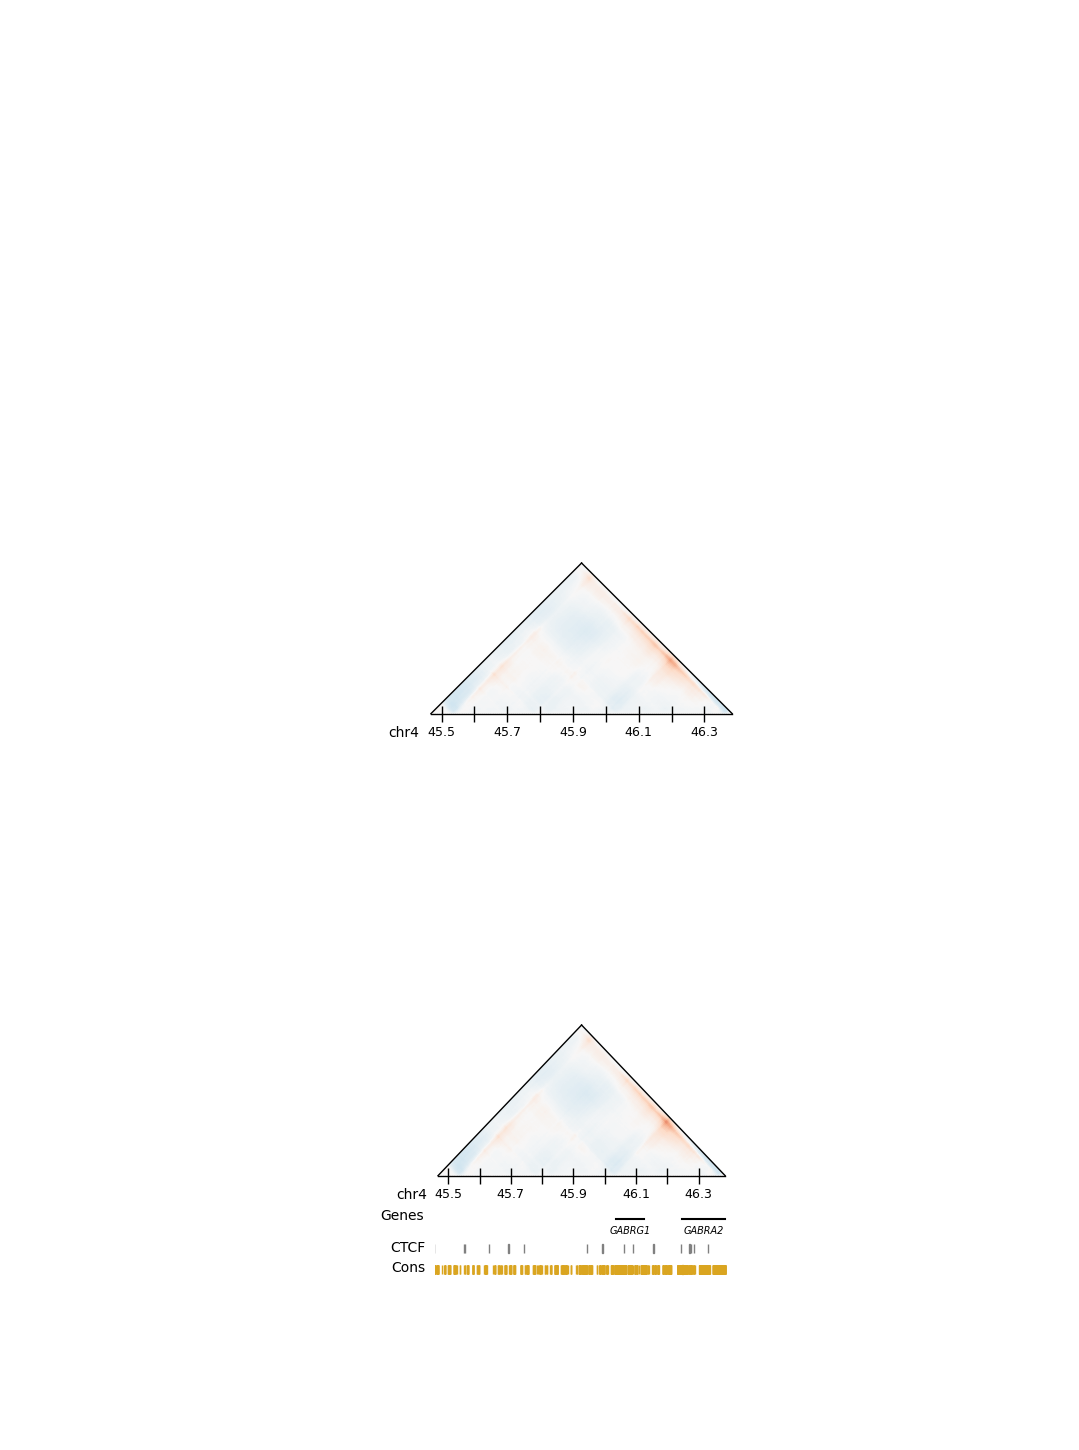

Comparisons saved.


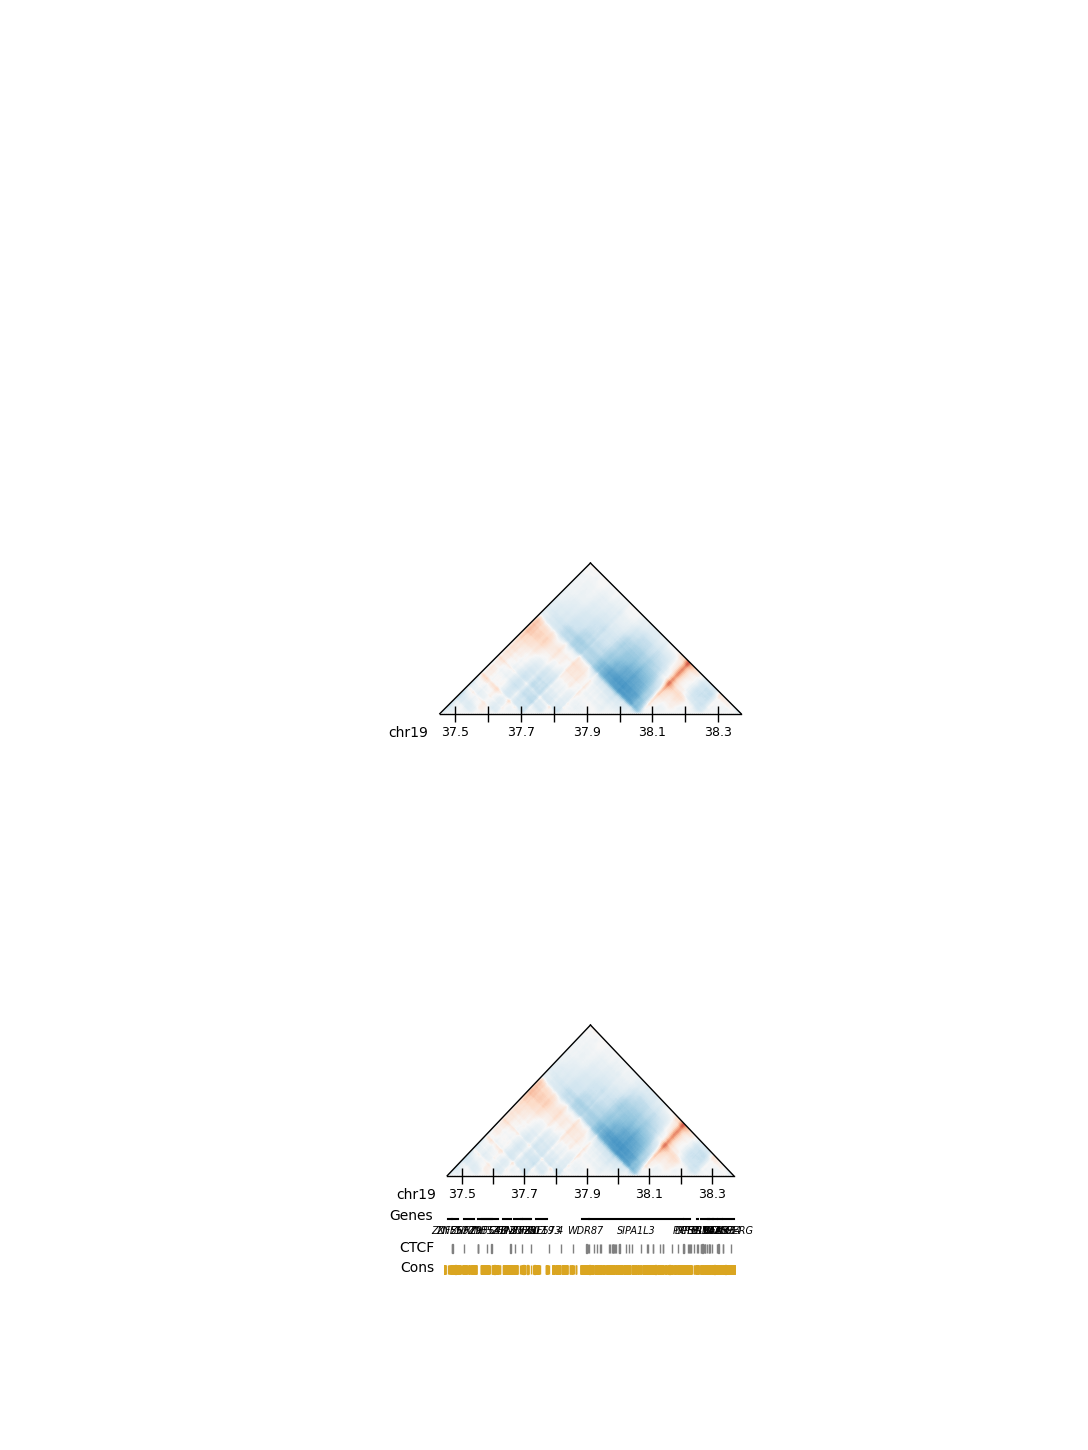

Comparisons saved.


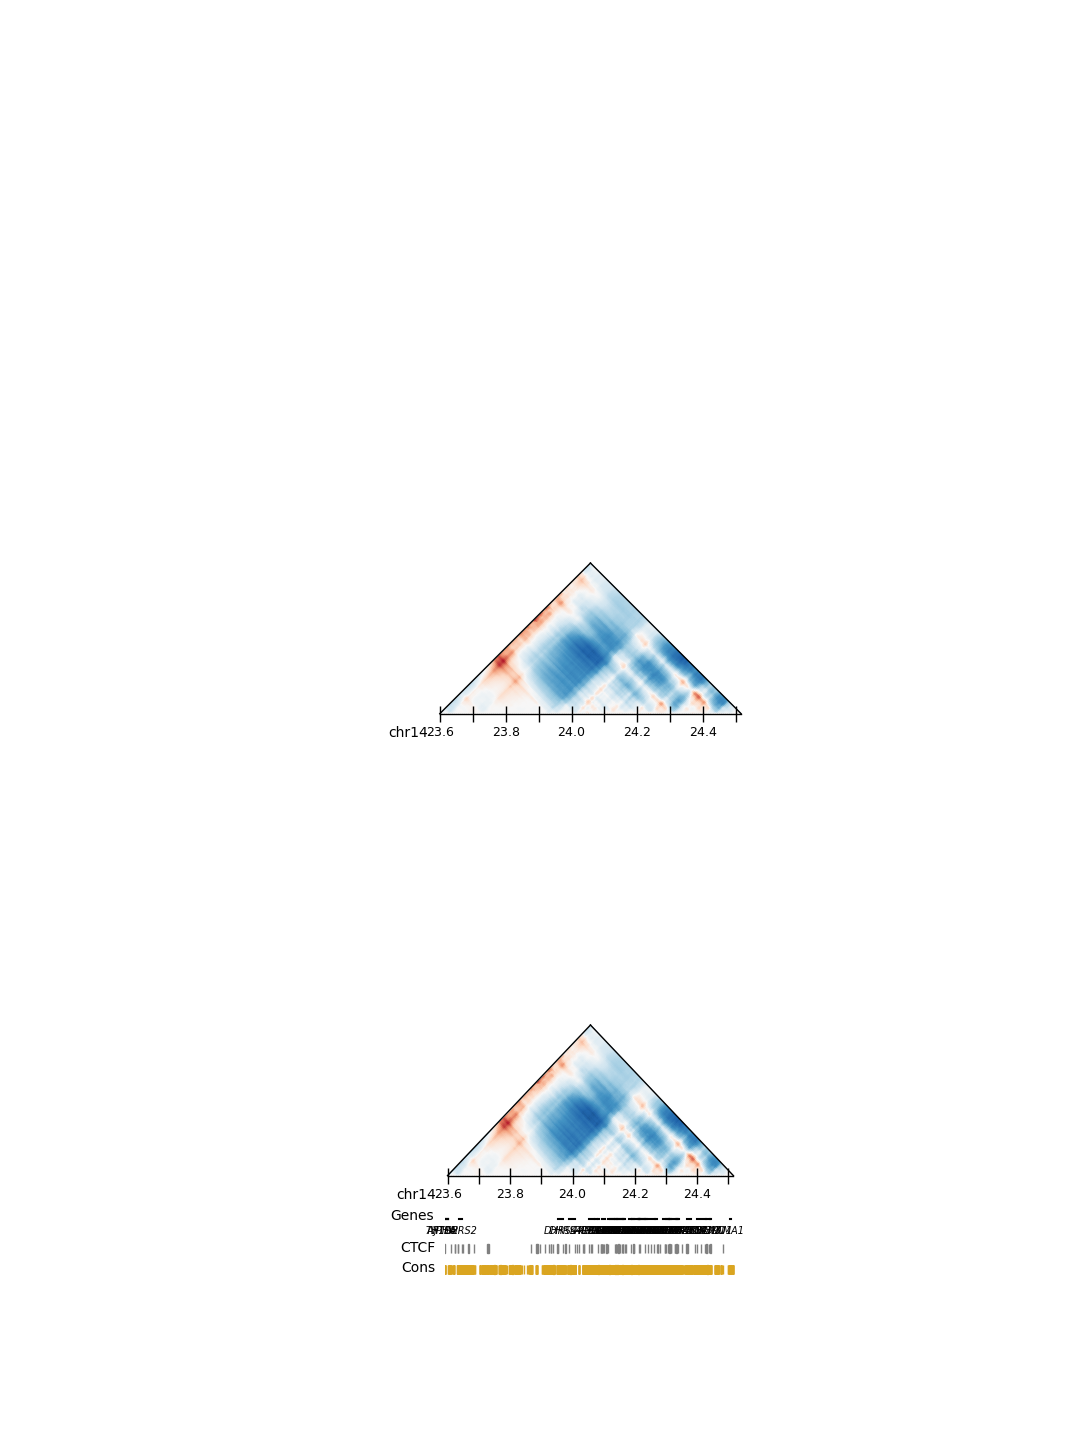

Comparisons saved.


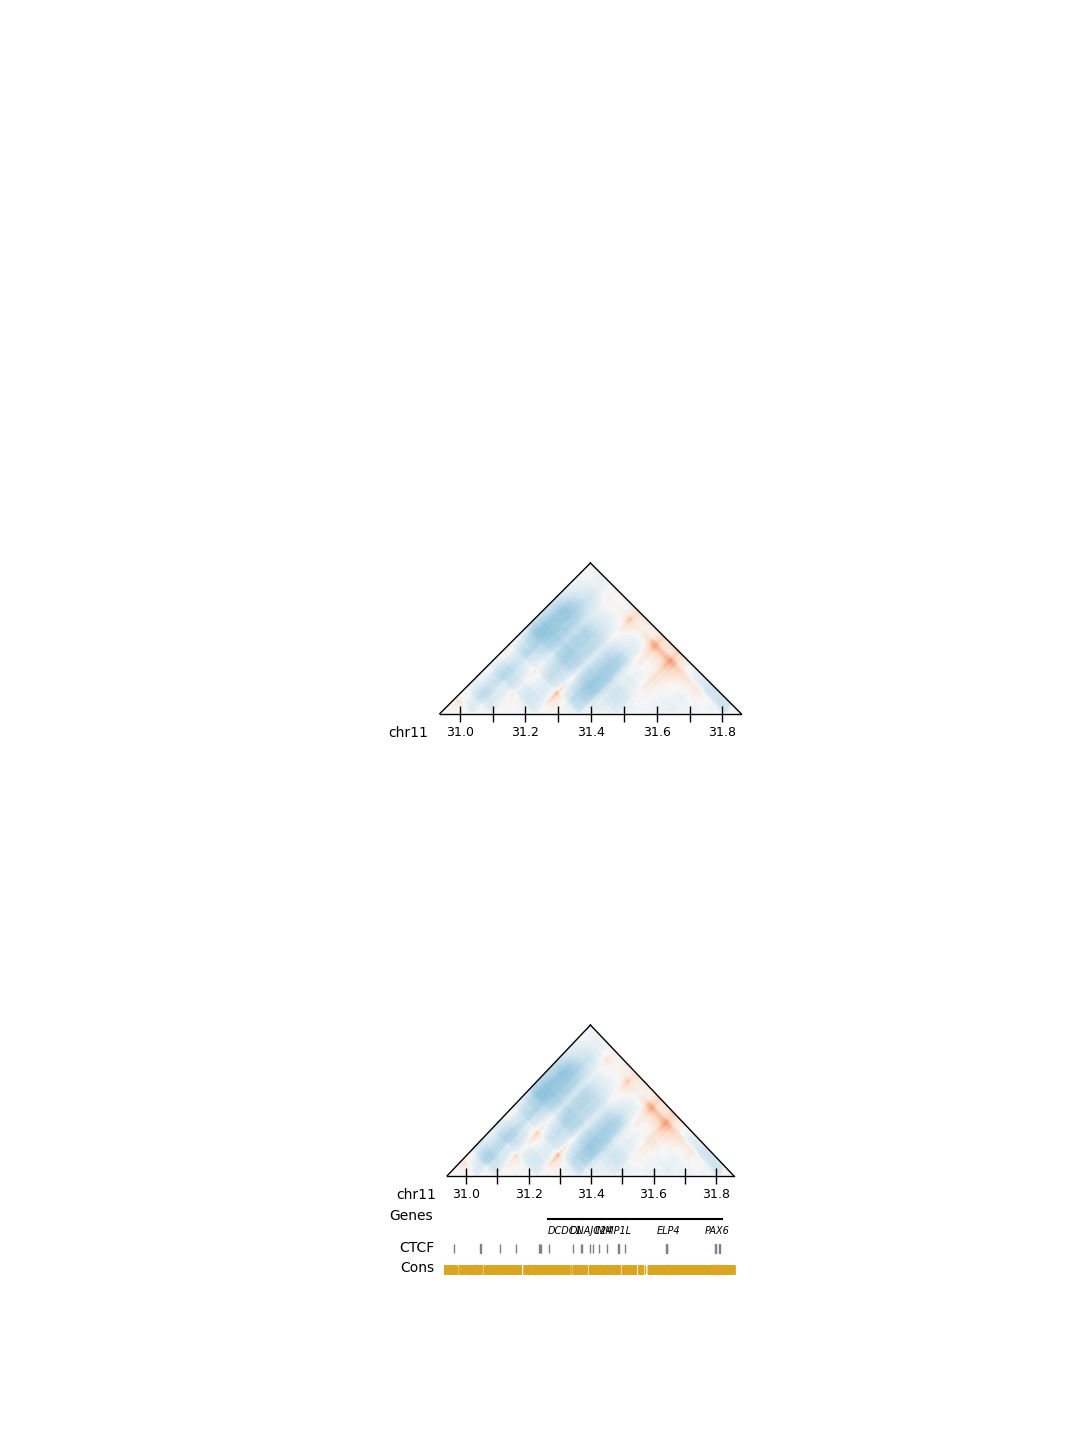

Comparisons saved.


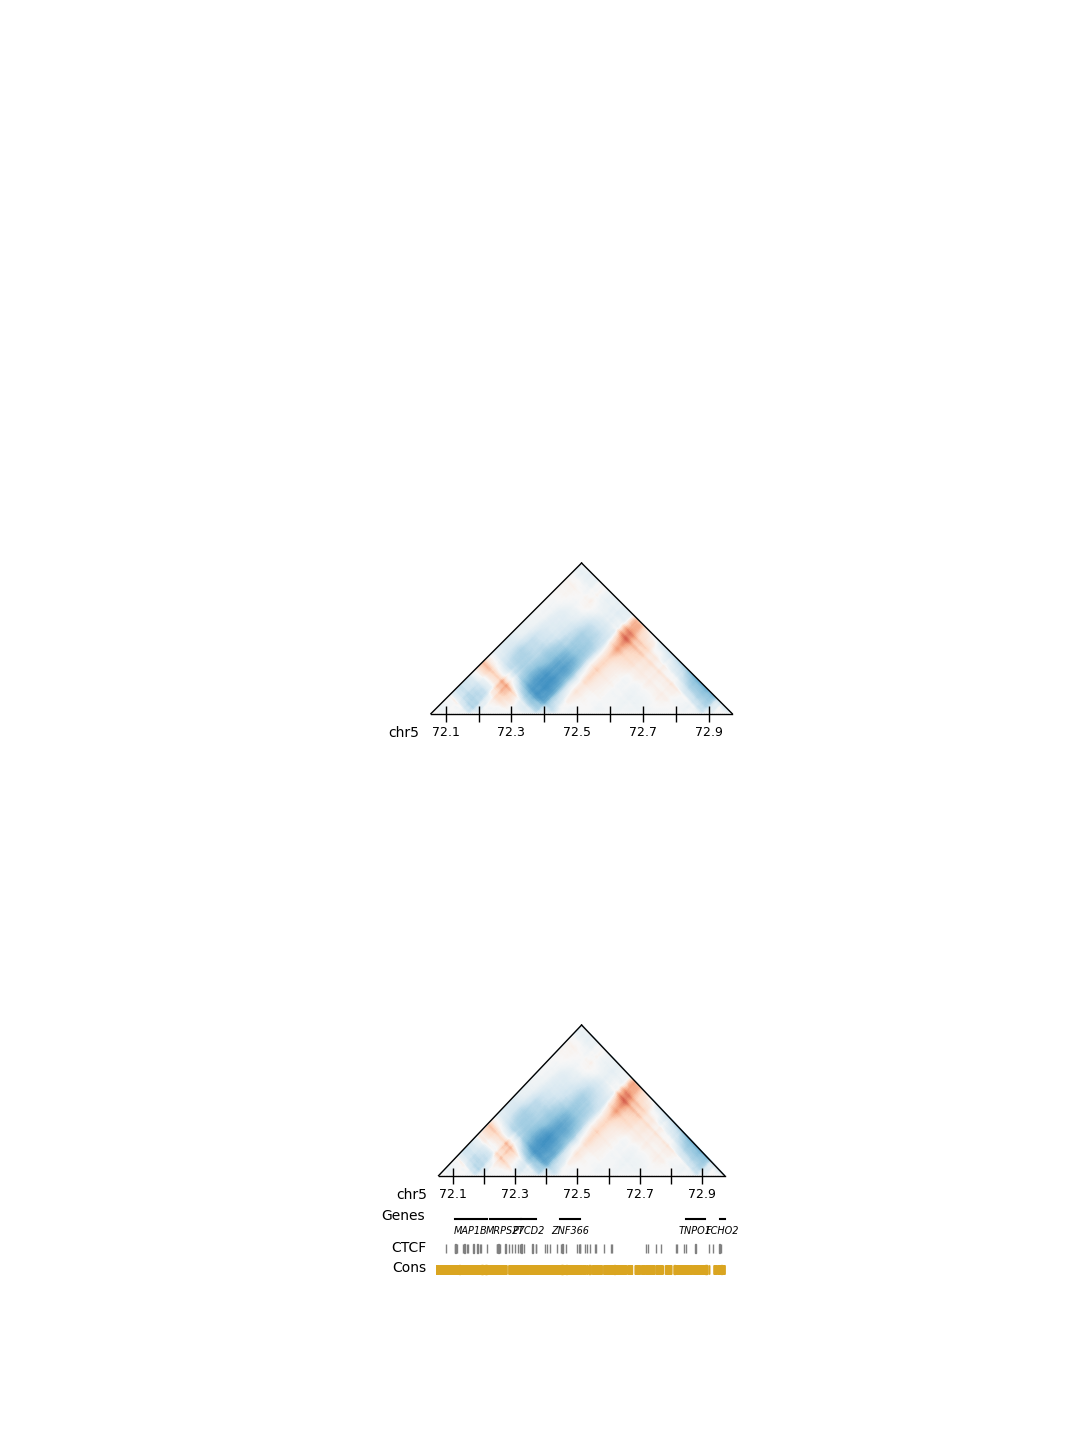

In [21]:
map_comparison_no_delta_with_annotations('/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_ALT5_EUR_10_96789820_T_C.txt','/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_ALT2_EUR_10_96789820_T_C.txt','chr10_96265532','yes', 10, 10,'chr10_96265532_TOEACH.pdf')

map_comparison_no_delta_with_annotations('/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_ALT14_EUR_3_46258274_A_G.txt','/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_ALT11_EUR_3_46258274_A_G.txt','chr3_45733986','yes', 10, 10,'chr3_45733986_TOEACH.pdf')

map_comparison_no_delta_with_annotations('/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_ALT6_EAS_12_104877307_G_T.txt','/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_ALT11_EAS_12_104877307_G_T.txt','chr12_104353019','yes', 10, 10,'chr12_104353019_TOEACH.pdf')

map_comparison_no_delta_with_annotations('/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_ALT6_EUR_4_122914501_C_A.txt','/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_ALT13_EUR_4_122914501_C_A.txt','chr4_122390213','yes', 10, 10,'chr4_122390213_TOEACH.pdf')

map_comparison_no_delta_with_annotations('/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_ALT17_EUR_9_106150630_A_G.txt','/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_ALT11_EUR_9_106150630_A_G.txt','chr9_105626342','yes', 10, 10,'chr9_105626342_TOEACH.pdf')

map_comparison_no_delta_with_annotations('/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_ALT7_EUR_9_34382728_A_G.txt','/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_ALT10_EUR_9_34382728_A_G.txt','chr9_33858440','yes', 10, 10,'chr9_33858440_TOEACH.pdf')

map_comparison_no_delta_with_annotations('/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_REF_EUR_6_104897150_T_C.txt','/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_ALT2_EUR_6_104897150_T_C.txt','chr6_104372862','yes', 10, 10,'chr6_104372862_TOEACH.pdf')

map_comparison_no_delta_with_annotations('/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_ALT5_EUR_14_65053528_T_C.txt','/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_ALT16_EUR_14_65053528_T_C.txt','chr14_64529240','yes', 10, 10,'chr14_64529240_TOEACH.pdf')

map_comparison_no_delta_with_annotations('/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_ALT7_EAS_5_78493049_G_C.txt','/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_ALT4_EAS_5_78493049_G_C.txt','chr5_77968761','yes', 10, 10,'chr5_77968761_TOEACH.pdf')

map_comparison_no_delta_with_annotations('/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_ALT5_EUR_4_45927155_A_G.txt','/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_ALT2_EUR_4_45927155_A_G.txt','chr4_45402867','yes', 10, 10,'chr4_45402867_TOEACH.pdf')

map_comparison_no_delta_with_annotations('/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_ALT8_EUR_19_37912459_T_C.txt','/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_ALT6_EUR_19_37912459_T_C.txt','chr19_37388171','yes', 10, 10,'chr19_37388171_TOEACH.pdf')

map_comparison_no_delta_with_annotations('/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_ALT7_EUR_14_24058463_G_A.txt','/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_ALT4_EUR_14_24058463_G_A.txt','chr14_23534175','yes', 10, 10,'chr14_23534175_TOEACH.pdf')

map_comparison_no_delta_with_annotations('/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_ALT2_EUR_11_31399033_G_A.txt','/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_ALT12_EUR_11_31399033_G_A.txt','chr11_30874745','yes', 10, 10,'chr11_30874745_TOEACH.pdf')

map_comparison_no_delta_with_annotations('/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_ALT6_EUR_5_72514419_G_A.txt','/Users/wanjun/Desktop/akita_visualize/akita_predictions/akita_ALT1_EUR_5_72514419_G_A.txt','chr5_71990131','yes', 10, 10,'chr5_71990131_TOEACH.pdf')
